## Leverage effect in equity-index and government-bond futures


**Dataset**
* daily relative price changes $r^i_t=(P^i_t-P^i_{t-1})/P^i_{t-1}$ for 10 futures contracts
* 5 equity indices and 5 government bonds, with the labels unknown
* date range 1982 to 2017

### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})

rng = np.random.default_rng(42)
H = 5  # forecast horizon in days


## OLS with Newey-West standard errors
def hac_ols(y, X, lags=2 * H):
    data = pd.concat([y, X], axis=1).dropna()
    return sm.OLS(data.iloc[:, 0], sm.add_constant(data.iloc[:, 1:])).fit(cov_type="HAC", cov_kwds={"maxlags": lags})


## Newey-West t-stat of a sample mean (used by the Diebold-Mariano test)
def hac_mean_t(d, lags):
    return sm.OLS(np.asarray(d), np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}).tvalues[0]


def sharpe(pnl):
    return pnl.mean() / pnl.std() * np.sqrt(252)

### 0. Data preparation

In [2]:
series = {f"INST{i}": pd.read_csv(f"../data/INST{i}.csv", header=None, index_col=0, parse_dates=True)[1]
          for i in range(10)}
raw = pd.concat(series, axis=1, sort=True).rename_axis("date")
instruments = list(raw.columns)

display(raw.tail())

,INST0,INST1,INST2,INST3,INST4,INST5,INST6,INST7,INST8,INST9
date,,,,,,,,,,
2017-10-19,6.162e-04,9.979e-04,1.330e-04,0.004,2.048e-03,1.953e-04,-4.046e-03,5.589e-03,0.001,-2.804e-03
2017-10-20,-5.203e-03,-3.505e-03,-4.657e-04,-0.005,-1.025e-03,5.245e-03,1.541e-04,-9.324e-04,0.002,-2.003e-04
2017-10-23,1.484e-03,7.505e-04,3.325e-04,0.002,-2.929e-04,-4.096e-03,1.385e-03,1.334e-02,-0.003,9.340e-04
2017-10-24,-3.538e-03,-1.503e-03,6.650e-05,-0.004,-1.613e-03,1.461e-03,1.536e-03,3.210e-03,0.001,7.333e-04
2017-10-25,NaN,NaN,-1.330e-04,-0.005,NaN,NaN,NaN,-2.298e-03,0.001,NaN


In [3]:
def statistics(r):
    """Coverage and distribution of one series, as read from its file."""
    life = pd.bdate_range(r.index[0], r.index[-1])
    q = r.quantile([0.05, 0.5, 0.95])
    return pd.Series({
        "first": r.index[0].date(),
        "last": r.index[-1].date(),
        "n_obs": len(r),
        "dup_dates": r.index.duplicated().sum(),
        "n_nan": r.isna().sum(),
        "n_inf": np.isinf(r).sum(),
        "missing_wkdays_per_yr": len(life.difference(r.index)) / len(life) * 261,
        "max_gap_days": r.index.to_series().diff().dt.days.max(),
        "weekend_rows": (r.index.dayofweek >= 5).sum(),
        "acf1": r.autocorr(),
        "skew": r.skew(),
        "excess_kurt": r.kurt(),
        "ann_vol_pct": 100 * r.std() * np.sqrt(252),
        "ann_mean_pct": 100 * r.mean() * 252,
        "p5_pct": 100 * q[0.05],
        "median_pct": 100 * q[0.5],
        "p95_pct": 100 * q[0.95],
    })

summary = pd.DataFrame({c: statistics(s) for c, s in series.items()})
summary

,INST0,INST1,INST2,INST3,INST4,INST5,INST6,INST7,INST8,INST9
first,1990-11-26,1982-05-04,1987-09-14,1982-11-19,1989-09-18,1997-09-10,1990-11-26,1988-09-07,2000-05-04,1984-05-04
last,2017-10-24,2017-10-24,2017-10-25,2017-10-25,2017-10-24,2017-10-24,2017-10-24,2017-10-25,2017-10-25,2017-10-24
n_obs,6808,8942,7384,8875,7060,5077,6807,7151,4467,8488
dup_dates,0,0,0,0,0,0,0,0,0,0
n_nan,0,0,0,0,0,0,0,0,0,0
n_inf,0,0,0,0,0,0,0,0,0,0
missing_wkdays_per_yr,7.954,8.882,15.744,6.844,9.682,8.601,7.991,15.452,5.38,7.322
max_gap_days,6.0,4.0,10.0,6.0,5.0,4.0,6.0,8.0,6.0,11.0
weekend_rows,0,1,0,0,0,0,0,0,1,0
acf1,0.007,0.023,-0.023,0.008,0.029,-0.063,0.004,-0.049,-0.023,-0.005


**Findings**
- data is clean: no duplicate dates, NaN or inf; the missing weekdays are consistent with exchange holidays
- start dates range from 1982 to 2000; all 10 overlap from 2000 to 2017
- two weekend rows (INST1 2016-03-12, INST8 2015-11-01); these futures have no weekend session, so we compound each into the next weekday, which keeps the price path exact
- skew is more negative for the higher-vol instruments: large down days are more common than large up days
- excess kurtosis 1.7 to 13: all series are fat-tailed, so our methods should be robust to extreme days rather than trim them

In [4]:
## fold the two weekend rows into the next weekday by compounding the returns

next_weekday = raw.index.to_series().where(raw.index.dayofweek < 5).bfill()
R = (1 + raw).groupby(next_weekday).prod(min_count=1) - 1

**Visualize price and vol over time**

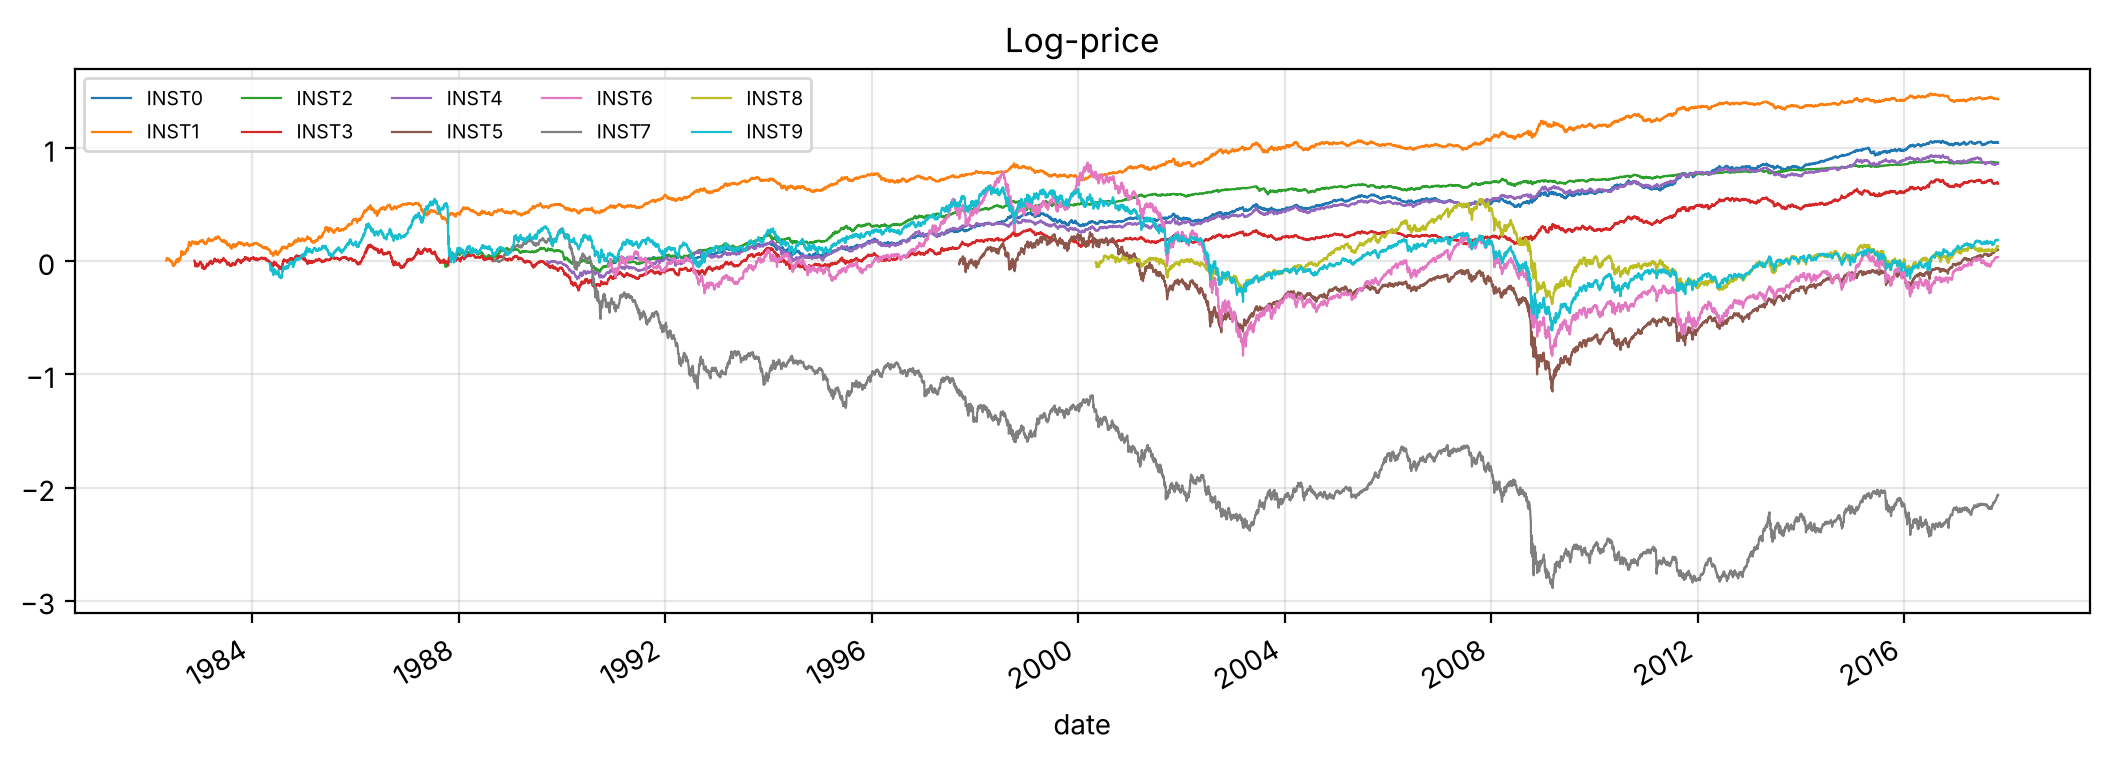

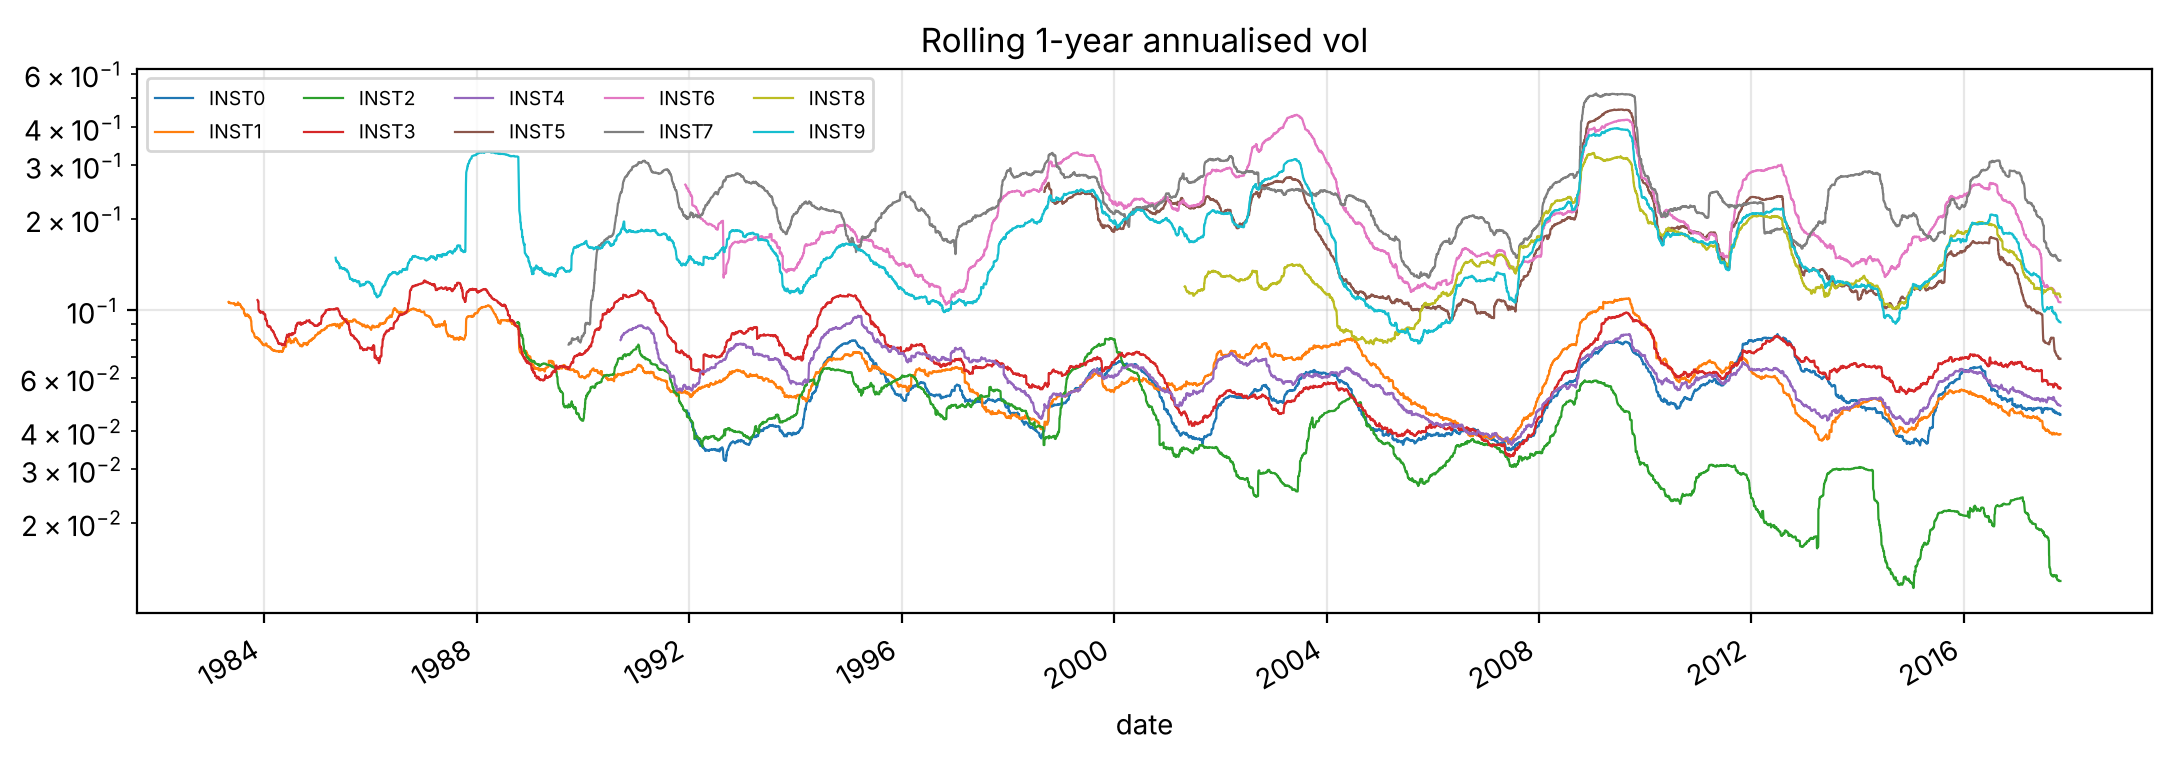

In [5]:
vol = R.apply(lambda r: r.dropna().rolling(252).std() * np.sqrt(252))
log_price = R.apply(lambda r: np.log1p(r.dropna()).cumsum())

ax = log_price.ffill().plot(lw=0.8, title="Log-price")
ax.legend(ncol=5, fontsize=7)
plt.show()

ax = vol.ffill().plot(lw=0.8, logy=True, title="Rolling 1-year annualised vol")
ax.legend(ncol=5, fontsize=7)
plt.show()

**Construct features**

| column | definition |
|---|---|
| `ret` | simple return $r_t=(P_t-P_{t-1})/P_{t-1}$, the roll-adjusted futures P&L per unit of notional |
| `vol` | $\sigma_t\sqrt{252}$, $\sigma_t$ = rolling 252-day standard deviation of $r$ |
| `ret_norm` | vol-normalised return $x_t=r_t/\sigma_{t-1}$ |
| `rv_1d` | $x_t^2$, one-day realised variance in units of $\sigma_{t-1}^2$ |
| `rv_5d` | mean of $x^2$ over the last 5 days |
| `rv_22d` | mean of $x^2$ over the last 22 days |
| `fwd_ret_5d` | $\sum_{i=1}^{5}r_{t+i}/\sigma_t$ |
| `fwd_var_5d` | $\frac{1}{5}\sum_{i=1}^{5}r_{t+i}^2/\sigma_t^2$ |

In [6]:
## each instrument stays on its own trading calendar, so a holiday never breaks a rolling window or stretches a lag

def build_features(r):
    r = r.dropna()
    sig = r.rolling(252).std()
    ret_norm = r / sig.shift(1)
    rv = ret_norm ** 2
    return pd.DataFrame({
        "ret": r,
        "vol": sig * np.sqrt(252),
        "ret_norm": ret_norm,
        "rv_1d": rv,
        "rv_5d": rv.rolling(5).mean(),
        "rv_22d": rv.rolling(22).mean(),
        "fwd_ret_5d": r.rolling(H).sum().shift(-H) / sig,
        "fwd_var_5d": (r ** 2).rolling(H).mean().shift(-H) / sig ** 2,
    }).dropna(subset=["rv_22d"])


features = {c: build_features(R[c]) for c in instruments}
features["INST0"]

,ret,vol,ret_norm,rv_1d,rv_5d,rv_22d,fwd_ret_5d,fwd_var_5d
date,,,,,,,,
1992-01-15,1.584e-03,0.043,0.579,0.335,1.333,0.727,-0.172,0.691
1992-01-16,-2.609e-03,0.043,-0.964,0.929,0.577,0.768,1.046,0.521
1992-01-17,1.246e-03,0.043,0.462,0.213,0.521,0.775,-0.046,0.557
1992-01-20,1.245e-03,0.043,0.461,0.213,0.536,0.741,-1.101,0.590
1992-01-21,2.596e-03,0.043,0.966,0.934,0.525,0.772,-0.887,0.679
...,...,...,...,...,...,...,...,...
2017-10-18,-2.713e-03,0.046,-0.941,0.886,0.710,0.498,NaN,NaN
2017-10-19,6.162e-04,0.045,0.213,0.046,0.686,0.495,NaN,NaN
2017-10-20,-5.203e-03,0.045,-1.818,3.305,1.048,0.634,NaN,NaN


### 1. Identify asset class with leverage effect

We use the leverage correlation function of Bouchaud, Matacz & Potters (2001), computed on normalized returns $\tilde x_t=x_t-\bar x$:
$$\mathcal{L}(\tau)=\frac{\operatorname{cov}(\tilde x_t,\;\tilde x^2_{t+\tau})}{\langle \tilde x^2\rangle^2}.$$
For τ>0 it measures how today's return relates to *future* squared returns. $\mathcal{L}(\tau)<0$ suggests a leverage effect. <br>
For τ<0 it measures how today's return relates to *past* volatility. <br> 
We also measure the **cumulative leverage** over one trading month, $S=\sum_{\tau=1}^{22}\mathcal{L}(\tau)$ (our summary statistic; there is no standard name). Since $x$ has variance $\approx1$, $S$ is about the slope of next month's summed squared returns on today's return: a $1\sigma$ fall adds about $|S|$ average days' worth of variance to the next 22 days. <br>
Then we fit the below function over $\tau\in[1,60]$ to get an amplitude and decay time:
$$\mathcal{L}(\tau)=-A\,e^{-\tau/T}$$

In [7]:
from scipy.optimize import curve_fit

TAUS = np.r_[-22:0, 1:61]
FUTURE_LAGS = (TAUS >= 1) & (TAUS <= 22)  # lags summed in S; 22 = one trading month
PAST_LAGS = TAUS < 0  # vol leads return, used in Q3


def leverage_corr(x, taus, variance=None):
    """L(tau) = cov(x_t, x_{t+tau}^2) / variance(x)^2. Each row of a 2-D x is a separate series.
    variance: the variance to scale by; by default each series' own."""
    v = np.atleast_2d(x)
    v = v - v.mean(axis=1, keepdims=True)
    if variance is None:
        variance = (v ** 2).mean(axis=1)
    out = []
    for t in taus:
        # pair each day's x with the x^2 tau days later (tau > 0) or earlier (tau < 0)
        a, b = (v[:, :-t], v[:, t:] ** 2) if t > 0 else (v[:, -t:], v[:, :t] ** 2)
        out.append(((a - a.mean(axis=1, keepdims=True)) * (b - b.mean(axis=1, keepdims=True))).mean(axis=1))
    return (np.array(out) / variance ** 2).T


def exp_decay(t, A, T):
    return -A * np.exp(-t / T)


L = {c: leverage_corr(features[c].ret_norm.values, TAUS)[0] for c in instruments}

rows = {}
for c in instruments:
    S = L[c][FUTURE_LAGS].sum()
    (A, T), _ = curve_fit(exp_decay, TAUS[TAUS > 0], L[c][TAUS > 0], p0=[0.2, 10], bounds=([-5, 0.5], [5, 250]))
    rows[c] = {"S": S, "L1": L[c][TAUS == 1][0], "A": A, "T_days": T}

q1 = pd.DataFrame(rows).T.sort_values("S")
q1

,S,L1,A,T_days
INST5,-3.118,-0.244,0.319,12.157
INST7,-2.760,-0.316,0.285,12.269
INST6,-2.491,-0.259,0.279,11.174
INST9,-2.131,-0.272,0.310,7.852
INST8,-1.935,-0.154,0.182,14.322
INST2,-1.292,-0.188,0.228,6.383
INST4,-0.447,-0.092,0.131,3.187
INST0,-0.409,-0.081,0.084,4.996
INST3,-0.306,-0.011,0.018,59.037
INST1,-0.216,-0.034,0.024,10.695


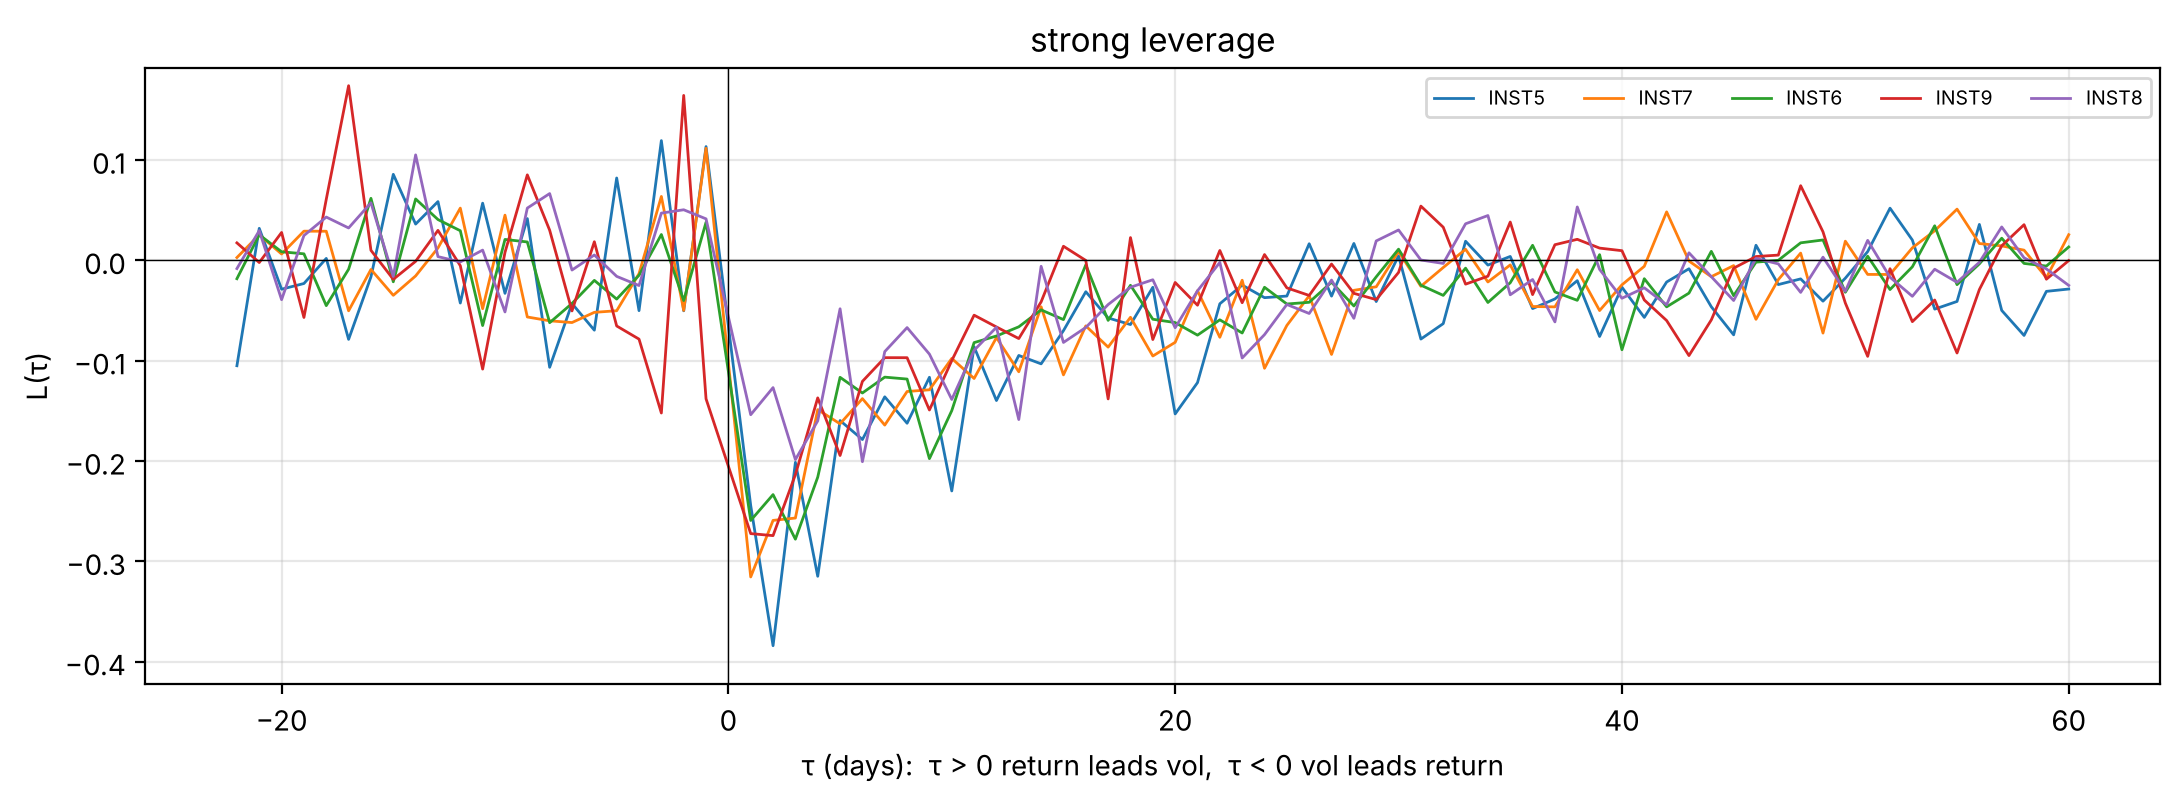

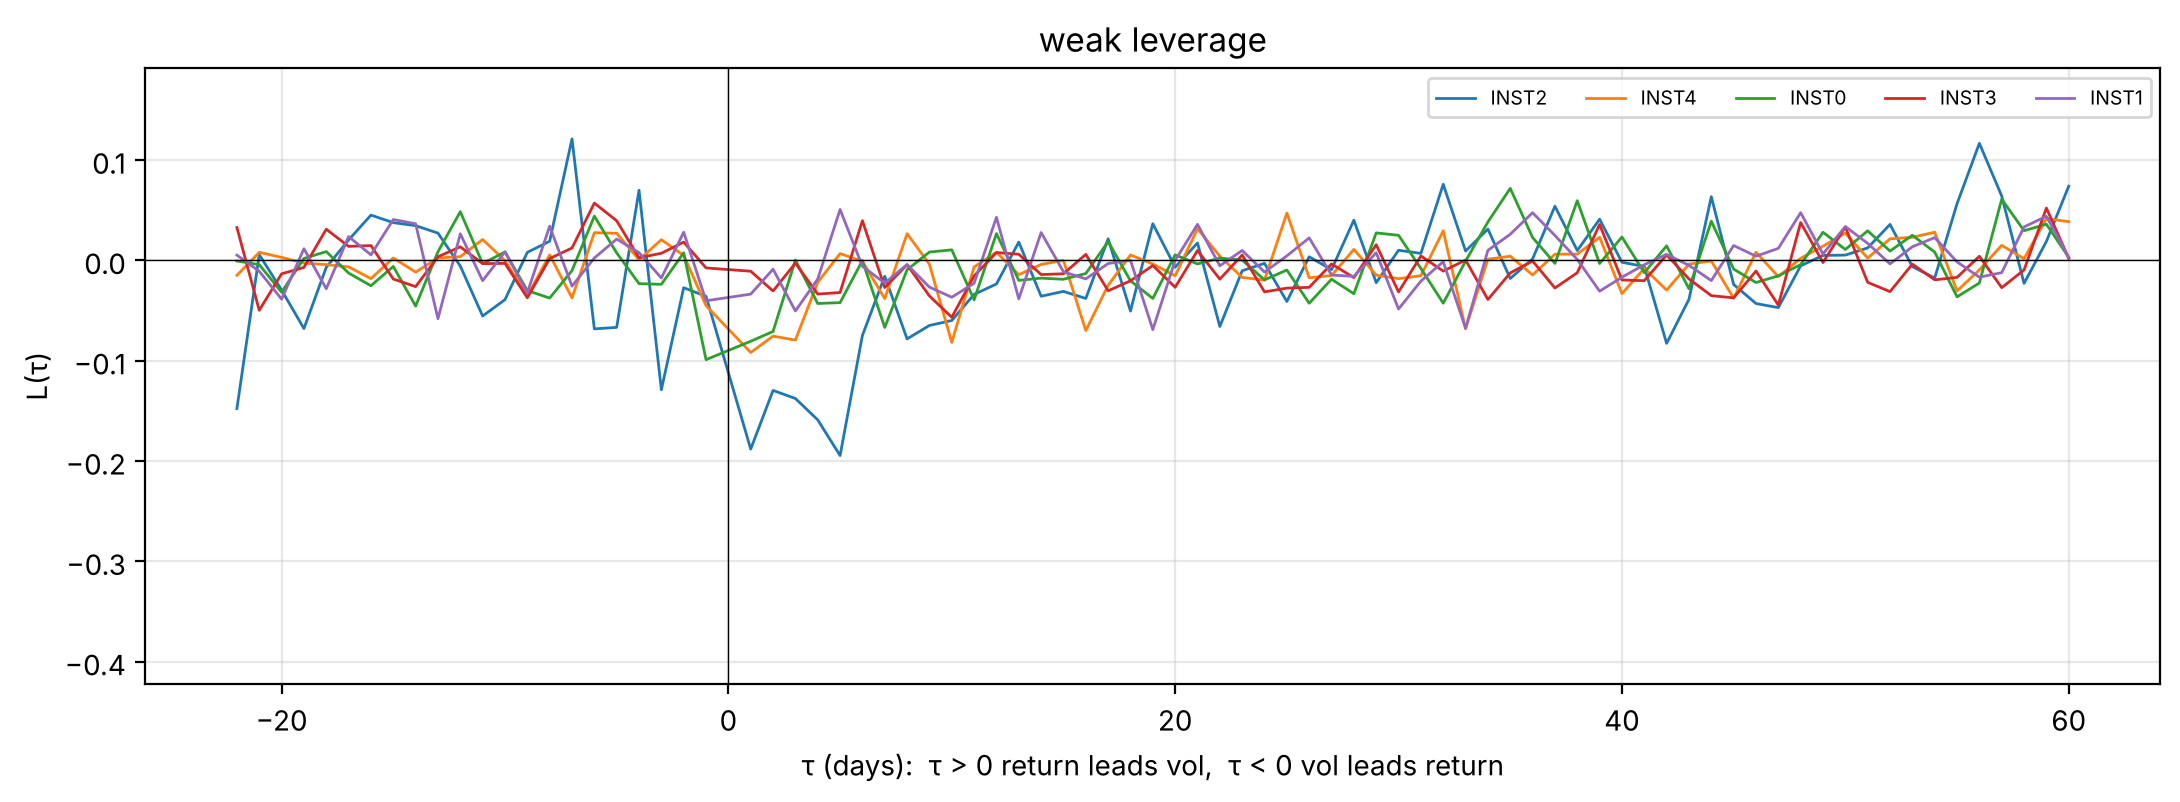

In [8]:
eq = list(q1.index[:5])  # strongest leverage
bd = list(q1.index[5:])

y_range = (1.1 * min(L[c].min() for c in instruments), 1.1 * max(L[c].max() for c in instruments))  # same scale for both
for group, title in ((eq, "strong leverage"), (bd, "weak leverage")):
    fig, ax = plt.subplots()
    for c in group:
        ax.plot(TAUS, L[c], lw=1, label=c)
    ax.axhline(0, c="k", lw=0.5)
    ax.axvline(0, c="k", lw=0.5)
    ax.set(title=title, xlabel="τ (days):  τ > 0 return leads vol,  τ < 0 vol leads return", ylabel="L(τ)", ylim=y_range)
    ax.legend(fontsize=7, ncol=5)
    plt.show()

**Correlation of the instruments' normalised returns**
* to further determine their asset class grouping

In [9]:
display(pd.DataFrame({c: features[c].ret_norm for c in instruments}).corr().round(2))

,INST0,INST1,INST2,INST3,INST4,INST5,INST6,INST7,INST8,INST9
INST0,1.00,0.57,0.13,0.77,0.55,-0.22,-0.13,-0.08,-0.10,-0.13
INST1,0.57,1.00,0.09,0.46,0.80,-0.29,-0.18,-0.04,-0.08,-0.08
INST2,0.13,0.09,1.00,0.13,0.09,-0.06,-0.07,-0.18,-0.21,-0.05
INST3,0.77,0.46,0.13,1.00,0.50,-0.22,-0.16,-0.08,-0.11,-0.01
INST4,0.55,0.80,0.09,0.50,1.00,-0.28,-0.15,-0.04,-0.06,-0.12
INST5,-0.22,-0.29,-0.06,-0.22,-0.28,1.00,0.58,0.15,0.15,0.52
INST6,-0.13,-0.18,-0.07,-0.16,-0.15,0.58,1.00,0.24,0.27,0.75
INST7,-0.08,-0.04,-0.18,-0.08,-0.04,0.15,0.24,1.00,0.58,0.28
INST8,-0.10,-0.08,-0.21,-0.11,-0.06,0.15,0.27,0.58,1.00,0.34
INST9,-0.13,-0.08,-0.05,-0.01,-0.12,0.52,0.75,0.28,0.34,1.00


**Conclusion**
- Ranking by cumulative leverage $S$ gives a 5/5 split with a gap between the groups: (-1.9 to -3.1) vs (-0.2 to -1.3)
- **Strong leverage group**: $A\approx0.2$-$0.3$ and $T\approx8$-14 days $\rightarrow$ **equity indices** (also the magnitudes Bouchaud et al. reported for stock indices)
- **Weak leverage group**: $S$ between -0.2 and -0.45 $\rightarrow$ **government bonds** (INST2 is the exception)
- Correlation confirms the split, where every equity pair is positively correlated, while every equity-bond pair is negatively correlated.
- INST2 exception: Its $\mathcal{L}(1)=-0.19$ and $A=0.23$ react like an equity index, but the effect fades in about 6 days instead of 8-14. Also, its returns correlate positively with every bond and negatively with every equity.

### 2. Significance and stability

**Hypothesis test for each instrument**
- $H_0$: no leverage effect. Given each day's size $|\tilde x_t|$, the direction of its price move is random, so $S$ is centred on 0.
- $H_1$: $S<0$ (leverage: falls are followed by more volatility). The hypothesis is directional and stated before looking at the data, so the primary test is **one-sided, left-tailed**, applied to all 10 instruments alike.
- Secondary (exploratory): a **two-sided** p-value, which would also flag an effect of the opposite sign. For bonds one could expect $S>0$ (flight to quality: bond prices rise when market-wide vol rises); none of the 10 instruments shows $S>0$, so this is reported only for completeness.
- Null distribution: $B=1000$ surrogate series $x^*_t=|\tilde x_t|\,\eta_t$ with $\eta_t=\pm1$, each as long as the data, then compute $S^*$ on each. The surrogates keep the actual vol clustering, fat tails and crash days, so the spread of $S^*$ is realistic.
- p-values: $p=(k+1)/(B+1)$ with $k$ = no. of $S^*\le S$ (one-sided) or of $|S^*|\ge|S|$ (two-sided). Decisions use $p$, with a Bonferroni threshold of $0.05/10=0.005$ for the 10 instruments; the floor $1/1001\approx0.001$ lies below it, so 1000 surrogates are enough to reject.
- $z=S/\operatorname{std}(S^*)$ is reported as a standardised effect size. It is not centred on the sample mean of $S^*$, because the null mean is 0 by symmetry (subtracting the simulated mean would only add simulation noise; it moves $z$ by at most 0.05 here). The $S^*$ distribution is close to normal, so $z$ also gives a resolution beyond the p-value floor.

In [10]:
def sign_flips(x, n=1000):
    return np.abs(x - x.mean()) * rng.choice([-1.0, 1.0], size=(n, len(x)))

def z_and_p(stat, null):
    """z = stat / std(null); one-sided p for H1: stat < 0, and two-sided p."""
    p_left = ((null <= stat).sum() + 1) / (len(null) + 1)
    p_two = ((np.abs(null) >= abs(stat)).sum() + 1) / (len(null) + 1)
    return stat / null.std(), p_left, p_two


BONFERRONI = 0.05 / len(instruments)

L_null = {c: leverage_corr(sign_flips(features[c].ret_norm.values), TAUS) for c in instruments}

rows = {}
for c in instruments:
    z, p, p_two = z_and_p(q1.S[c], L_null[c][:, FUTURE_LAGS].sum(axis=1))
    rows[c] = {"S": q1.S[c], "z": z, "p_one_sided": p, "p_two_sided": p_two, "reject_bonferroni": p <= BONFERRONI}
pd.DataFrame(rows).T

,S,z,p_one_sided,p_two_sided,reject_bonferroni
INST0,-0.409,-1.863,0.026,0.062,False
INST1,-0.216,-1.207,0.119,0.227,False
INST2,-1.292,-3.536,0.001,0.001,True
INST3,-0.306,-1.604,0.055,0.118,False
INST4,-0.447,-2.405,0.01,0.017,False
INST5,-3.118,-5.02,0.001,0.001,True
INST6,-2.491,-6.335,0.001,0.001,True
INST7,-2.76,-5.87,0.001,0.001,True
INST8,-1.935,-5.66,0.001,0.001,True
INST9,-2.131,-5.095,0.001,0.001,True


**Stability over time**
- We obtain $S$ per calendar year by computing $\mathcal{L}(\tau)$ for $\tau\in[1,22]$ within each calendar year (years with at least 200 trading days, so a partial first year is dropped; the partial year 2017 has about 205 days and is kept).
- Scale each year's leverage by full-sample variance $\langle\tilde x^2\rangle^2$ instead of its own. A single year's $\langle\tilde x^2\rangle$ is driven by a few big days, so dividing by it would make calm years look extreme. And using one scale also allows for comparison of the covariance/$S$ across years.

There are only 16 to 34 yearly values per instrument, and they are heavy-tailed (crisis years reach -8 to -16), so the tests are chosen for small samples:
- `sign_test_p`: exact one-sided binomial test that more than half of the years have $S<0$.
- `slope`, `slope_p_hc3`: OLS trend of yearly $S$ on year with HC3 robust errors and a $t(n-2)$ reference (HC0 with a normal reference over-rejects at this sample size).
- `slope_p_perm`: permutation test of the OLS slope (10,000 random orderings of the years; needs no distributional assumption, only that years are exchangeable under no trend; lag-1 autocorrelation of yearly $S$ is between -0.17 and 0.02).
- `theil_sen`, `kendall_p`: Theil-Sen slope and the exact Mann-Kendall (Kendall's $\tau$ against year) test, both rank-based and therefore not driven by the few crisis years.

Yearly values differ in precision mostly because of the vol regime, not the number of days (202 to 259 days per year); weighting the regression by days changes no slope by more than 0.01.

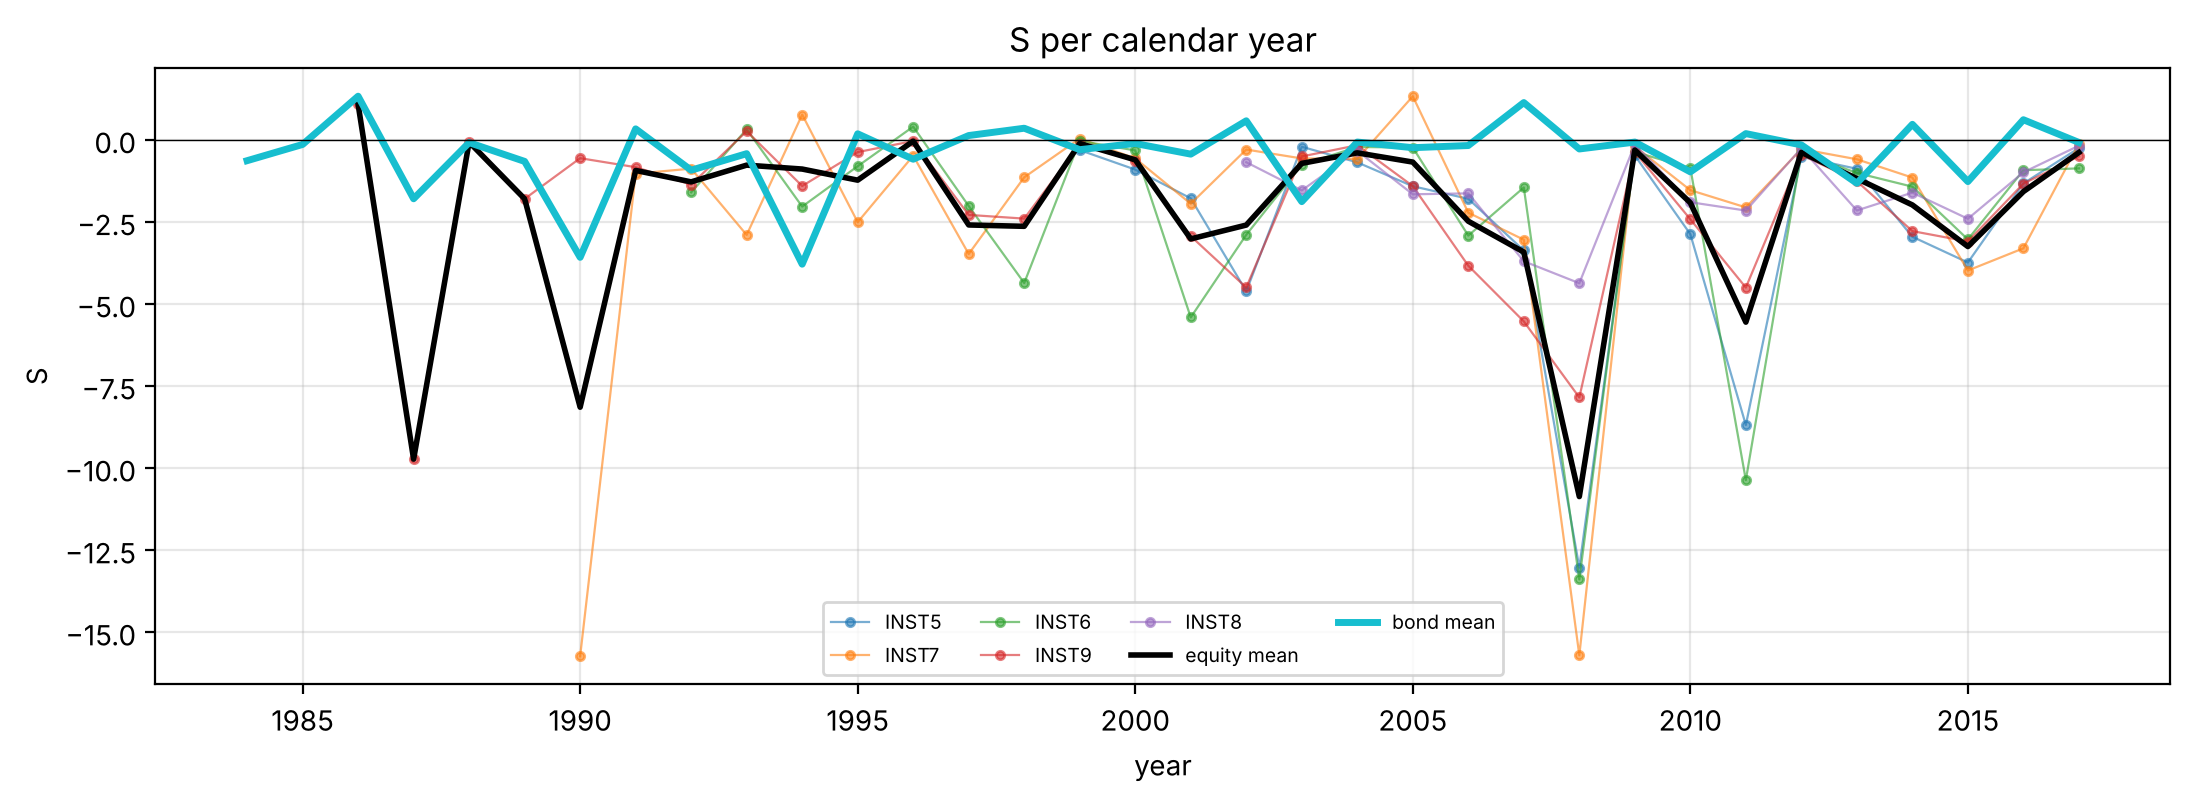

,n_years,pct_years_neg,sign_test_p,slope,slope_p_hc3,slope_p_perm,theil_sen,kendall_p
INST0,26.0,57.692,2.786e-01,-0.004,0.943,0.919,5.250e-03,0.793
INST1,34.0,61.765,1.147e-01,0.013,0.540,0.566,1.383e-02,0.345
INST2,29.0,62.069,1.325e-01,0.078,0.167,0.195,2.950e-02,0.342
INST3,34.0,67.647,2.881e-02,0.024,0.373,0.320,1.670e-02,0.147
INST4,27.0,55.556,3.506e-01,0.028,0.540,0.421,4.572e-03,0.773
INST5,19.0,100.000,1.907e-06,-0.053,0.584,0.722,-4.081e-02,0.534
INST6,26.0,92.308,5.245e-06,-0.063,0.335,0.483,-3.365e-02,0.314
INST7,28.0,89.286,1.372e-05,0.054,0.659,0.586,4.804e-04,1.000
INST8,16.0,100.000,1.526e-05,0.016,0.805,0.822,-5.475e-03,0.965
INST9,32.0,93.750,1.232e-07,-0.032,0.591,0.490,-4.864e-02,0.077


In [11]:
from scipy import stats


## S for one calendar year: the Q1 formula on that year's days only, scaled by the full-sample variance
def yearly_S(x, min_days=200):
    full_sample_variance = x.var(ddof=0)
    return x.groupby(x.index.year).apply(
        lambda s: leverage_corr(s.values, TAUS[FUTURE_LAGS], variance=full_sample_variance)[0].sum() if len(s) >= min_days else np.nan)

## persistence and trend of one instrument's yearly S, with small-sample tests
def stability(s, n_perm=10_000):
    s = s.dropna()
    year = s.index.values.astype(float)
    fit = sm.OLS(s.values, sm.add_constant(year)).fit(cov_type="HC3", use_t=True)  # t(n-2) reference
    centred = year - year.mean()
    perm = np.random.default_rng(0).permuted(np.tile(s.values, (n_perm, 1)), axis=1)
    perm_slopes = perm @ centred / (centred @ centred)
    n_neg = int((s < 0).sum())
    return pd.Series({
        "n_years": len(s),
        "pct_years_neg": 100 * n_neg / len(s),
        "sign_test_p": stats.binomtest(n_neg, len(s), 0.5, alternative="greater").pvalue,
        "slope": fit.params[1],
        "slope_p_hc3": fit.pvalues[1],
        "slope_p_perm": ((np.abs(perm_slopes) >= abs(fit.params[1])).sum() + 1) / (n_perm + 1),
        "theil_sen": stats.theilslopes(s.values, year).slope,
        "kendall_p": stats.kendalltau(year, s.values, method="exact").pvalue,
    })


yearly = pd.DataFrame({c: yearly_S(features[c].ret_norm) for c in instruments})

fig, ax = plt.subplots()
yearly[eq].plot(ax=ax, lw=0.8, alpha=0.6, marker=".")
yearly[eq].mean(axis=1).plot(ax=ax, c="k", lw=2, label="equity mean")
yearly[bd].mean(axis=1).plot(ax=ax, c="tab:cyan", lw=2.5, label="bond mean")
ax.axhline(0, c="k", lw=0.5)
ax.set(title="S per calendar year", xlabel="year", ylabel="S")
ax.legend(fontsize=7, ncol=4)
plt.show()

yearly.apply(stability).T

**Findings**
- With the one-sided test and a Bonferroni threshold of $p\le0.005$, we reject the null of no leverage effect for all 5 equity indices ($p$ at the floor 0.001, $z$ from -5.0 to -6.3) and for one bond, INST2 ($z=-3.5$). INST4 ($p=0.010$) and INST0 ($p=0.026$) are below 0.05 one-sided but do not survive the correction. The two-sided p-values lead to the same decisions.
- **Bonds**
    - no stable effect: $S<0$ in only 56-68% of years (sign test $p\ge0.029$, none below the Bonferroni 0.005) and the bond mean hovers around zero.
    - no trend: no slope test is significant (HC3 $p\ge0.17$, permutation $p\ge0.19$, Mann-Kendall $p\ge0.15$).
- **Equities**
    - significant and persistent effect: $S<0$ in 89-100% of calendar years (sign test $p\le2\times10^{-5}$ for each index).
    - no trend: no evidence of a trend (HC3 $p$ from 0.34 to 0.81, permutation $p$ from 0.48 to 0.82, Mann-Kendall $p$ from 0.08 to 1.00) and the signs are mixed. With only 16-32 yearly points per instrument, only a fairly large trend could be detected.
    - most of the leverage effect is made in stress years: Yearly $S$ is around -1 to -3 in normal years and drops to -8 to -16 in 1987, 1990, 2008 and 2011.

### 3. Returns predict volatility vs volatility predicts returns

We test the leverage correlation in section 1 with sign flips in both directions (Bouchaud et al. 2001).
- **Returns → vol** (`z_ret_to_vol`): today's return vs squared returns over the *next* 22 days, $\tau\in[1,22]$.
- **Vol → returns** (`z_vol_to_ret`): today's return vs squared returns over the *previous* 22 days, $\tau\in[-22,-1]$.

We build the OLS model with the following regressors and regressands.

$$\text{returns}\to\text{vol:}\quad \overline{x^2}_{t+1:t+5}=c+\beta_d\,x_t^2+\beta_w\,\overline{x^2}_{t-4:t}+\beta_m\,\overline{x^2}_{t-21:t}+\gamma\,x_t+\delta\,|x_t|+\varepsilon$$
$$\text{vol}\to\text{returns:}\quad x_{t+1:t+5}=c'+\beta'_d\,x_t^2+\beta'_w\,\overline{x^2}_{t-4:t}+\beta'_m\,\overline{x^2}_{t-21:t}+\gamma'\,x_t+\delta'\,|x_t|+\varepsilon'$$

- today's variance $x_t^2$, past-week variance, past-month variance
    - due to high autocorrelation of volatility, we control for vol persistence using the HAR model (Corsi, 2009).
- today's signed return $x_t$ and its size $\lvert x_t\rvert$
    - $\gamma$ is the leverage effect, negative means today's return and next week's vol move in opposite directions, *beyond* vol persistence.
    - $\delta$ captures that a big move in *either* direction raises vol. It is there so that $\gamma$ measures only the effect of the move's *direction*.
- target horizon of 5 days: the average of five squared returns reduces the noise, and a week sits inside the 8-14-day decay of $\mathcal{L}$.

Others
* We fit the OLS with Newey-West (HAC) standard errors over 10 lags, because neighboring 5-day targets overlap.
* Returns are fat-tailed (excess kurtosis 1.7-13), so there are far more extreme days than a normal distribution. A few crash days can skew the OLS fit. We rerun both tests without the two crashes (Oct-Dec 1987 and 15 Sep-Dec 2008), `ex_crises`.
* We also compare the share of target's variance, **R²**, explained with and without the main regressor, to ensure that the model is not built solely based on the vol persistence.

In [12]:
HAR = ["rv_1d", "rv_5d", "rv_22d"]
RET = ["ret_norm", "abs_ret_norm"]
VOL_TERMS_ZERO = "rv_1d = rv_5d = rv_22d = 0"


def ex_crises(idx):
    crash_87 = (idx >= "1987-10-01") & (idx <= "1987-12-31")
    crash_08 = (idx >= "2008-09-15") & (idx <= "2008-12-31")
    return ~(crash_87 | crash_08)


ret_to_vol, vol_to_ret = {}, {}
for inst in instruments:
    feat = features[inst].assign(abs_ret_norm=features[inst].ret_norm.abs())
    calm = ex_crises(feat.index)

    ret_to_vol_model = hac_ols(feat.fwd_var_5d, feat[HAR + RET])
    ret_to_vol_calm = hac_ols(feat.fwd_var_5d[calm], feat.loc[calm, HAR + RET])
    har_model = hac_ols(feat.fwd_var_5d, feat[HAR])

    vol_to_ret_model = hac_ols(feat.fwd_ret_5d, feat[HAR + RET])
    vol_to_ret_calm = hac_ols(feat.fwd_ret_5d[calm], feat.loc[calm, HAR + RET])
    ret_model = hac_ols(feat.fwd_ret_5d, feat[RET])

    ret_to_vol[inst] = {
        "z_ret_to_vol": z_and_p(L[inst][FUTURE_LAGS].sum(), L_null[inst][:, FUTURE_LAGS].sum(axis=1))[0],
        "gamma": ret_to_vol_model.params["ret_norm"],
        "gamma_p_value": ret_to_vol_model.pvalues["ret_norm"],
        "gamma_p_value_ex_crises": ret_to_vol_calm.pvalues["ret_norm"],
        "delta": ret_to_vol_model.params["abs_ret_norm"],
        "delta_p_value": ret_to_vol_model.pvalues["abs_ret_norm"],
        "R2_without_ret": har_model.rsquared,
        "R2_with_ret": ret_to_vol_model.rsquared,
    }
    vol_to_ret[inst] = {
        "z_vol_to_ret": z_and_p(L[inst][PAST_LAGS].sum(), L_null[inst][:, PAST_LAGS].sum(axis=1))[0],
        "beta_p_value": float(vol_to_ret_model.f_test(VOL_TERMS_ZERO).pvalue),
        "beta_p_value_ex_crises": float(vol_to_ret_calm.f_test(VOL_TERMS_ZERO).pvalue),
        "R2_without_vol": ret_model.rsquared,
        "R2_with_vol": vol_to_ret_model.rsquared,
    }

print("Returns -> vol: target = next 5 days' variance")
display(pd.DataFrame(ret_to_vol).T)
print("Vol -> returns: target = next 5 days' return")
pd.DataFrame(vol_to_ret).T

Returns -> vol: target = next 5 days' variance


,z_ret_to_vol,gamma,gamma_p_value,gamma_p_value_ex_crises,delta,delta_p_value,R2_without_ret,R2_with_ret
INST0,-1.863,-0.033,3.037e-02,2.445e-02,-0.068,1.636e-01,0.149,0.151
INST1,-1.207,-0.010,4.490e-01,1.335e-01,0.019,7.416e-01,0.106,0.106
INST2,-3.536,-0.130,9.304e-05,6.509e-05,0.277,5.541e-04,0.109,0.117
INST3,-1.604,-0.025,6.723e-02,5.422e-02,0.100,7.665e-02,0.094,0.095
INST4,-2.405,-0.048,1.352e-02,1.760e-03,0.069,1.308e-01,0.089,0.091
INST5,-5.020,-0.251,6.380e-07,1.417e-07,0.070,3.576e-01,0.201,0.223
INST6,-6.335,-0.217,2.056e-08,2.136e-08,0.093,3.827e-01,0.224,0.247
INST7,-5.870,-0.215,3.348e-07,5.306e-12,-0.022,8.656e-01,0.194,0.208
INST8,-5.660,-0.145,4.388e-10,7.953e-10,0.114,9.960e-02,0.181,0.195
INST9,-5.095,-0.196,2.654e-05,6.302e-14,0.330,1.114e-03,0.046,0.055


Vol -> returns: target = next 5 days' return


,z_vol_to_ret,beta_p_value,beta_p_value_ex_crises,R2_without_vol,R2_with_vol
INST0,-0.960,9.620e-01,9.321e-01,1.492e-03,1.689e-03
INST1,-0.099,9.780e-01,9.952e-01,4.714e-04,5.522e-04
INST2,-0.689,7.269e-01,7.213e-01,9.086e-04,1.853e-03
INST3,0.469,1.511e-01,2.204e-01,1.102e-04,2.169e-03
INST4,-0.249,8.667e-02,8.390e-02,4.711e-04,2.064e-03
INST5,-0.027,7.214e-01,7.772e-02,4.440e-03,5.479e-03
INST6,-0.097,2.900e-01,3.430e-01,2.314e-04,3.014e-03
INST7,-0.274,3.008e-02,1.106e-01,1.923e-04,4.302e-03
INST8,1.207,2.197e-01,1.509e-02,1.754e-03,4.750e-03
INST9,-0.092,3.126e-06,8.217e-04,3.421e-04,5.416e-03


**Conclusion**
- **Returns movement predicts vol**
    - For all 5 equity indices $\gamma<0$ with $p<10^{-4}$ after controlling for past vol, also without the crises (`gamma_p_value_ex_crises`), suggesting that falls in equity returns raise next week's vol and rallies lower it. $\delta$ is insignificant for 4 of the 5 (INST9 is the exception), meaning a fall raises vol by about as much as a rally of the same size lowers it. Adding the return terms raises the variance forecast's R² by 0.9-2.3 percentage points.
- **Vol movements do not predict returns**
    - `beta_p_value` is an F-test of $H_0$: $\beta'_d=\beta'_w=\beta'_m=0$, i.e. past vol does not predict returns. We do a joint test because the vol terms are highly correlated. Apart from INST9, no instrument rejects $H_0$ in both the full sample and ex-crises. This matches Bouchaud et al. (2001), who found $\mathcal{L}(\tau<0)\approx0$ for stock indices.
- **Limitation**
    - Use of daily close data does not allow us to measure intraday volatility feedback.

## 4. Cross-category effects

We find out if equity/bond movements affect the other category's volatility, *beyond* each market's own leverage and vol persistence.

We add the *source* market's same-day return and its size ($\theta\,y_t+\theta_a\,|y_t|$) to the *target* market's section 3 model.
$$\overline{x^2}_{t+1:t+5}=\underbrace{c+\beta_d\,x_t^2+\beta_w\,\overline{x^2}_{t-4:t}+\beta_m\,\overline{x^2}_{t-21:t}+\gamma\,x_t+\delta\,|x_t|}_{\text{target market's own terms (section 3)}}+\theta\,y_t+\theta_a\,|y_t|+\varepsilon$$

- $\theta<0$: a *fall* in the *source* market predicts higher vol in the *target* market.
- To prevent lookahead, we use *source* data known on day t to forecast the *target* from day t+1 onwards, assuming both markets close on the same day.

We test each category as a whole and on individual pairs.
- **Baskets** (main test): the average of the 5 equities and of the 5 bonds trading that day, to reduce noise.
- **Pairs:** we find a bond and an equity with near-identical holiday calendars, and check their individual relationship.

In [13]:
weekdays = pd.bdate_range("2002-01-01", "2017-10-20")
closed = pd.DataFrame({c: ~weekdays.isin(R[c].dropna().index) for c in instruments}, index=weekdays)


## share of the two markets' closed weekdays that they share: days both closed / days either closed
def jaccard_holiday_overlap(a, b):
    return (a & b).sum() / (a | b).sum()


overlap = pd.DataFrame({e: {b: jaccard_holiday_overlap(closed[b], closed[e]) for b in sorted(bd)} for e in sorted(eq)})
display(overlap.round(2))
pairs = [(b, overlap.loc[b].idxmax()) for b in overlap.index if overlap.loc[b].max() > 0.8]
print(f"(bond, equity) pairs with similar calendar: \n{pairs}")

,INST5,INST6,INST7,INST8,INST9
INST0,0.21,1.00,0.07,0.52,0.53
INST1,0.95,0.20,0.05,0.21,0.23
INST2,0.04,0.07,0.98,0.05,0.05
INST3,0.23,0.61,0.04,0.67,0.82
INST4,0.28,0.22,0.08,0.33,0.26


(bond, equity) pairs with similar calendar: 
[('INST0', 'INST6'), ('INST1', 'INST5'), ('INST2', 'INST7'), ('INST3', 'INST9')]


In [14]:
def basket(cols):
    """Cross-sectional mean over the instruments trading that day."""
    stacked = pd.concat({c: features[c][["ret_norm", "rv_1d", "rv_5d", "rv_22d", "fwd_var_5d"]] for c in cols}, axis=1, sort=True)
    return stacked.T.groupby(level=1).mean().T  # mean over instruments, per feature


SRC = ["src_ret", "src_abs_ret"]


## on the same days: the target's section 3 vol model without and with the source's same-day return and its size
def cross_reg(target, source):
    src_ret = source.ret_norm.reindex(target.index)
    data = target.assign(
        abs_ret_norm=target.ret_norm.abs(),
        src_ret=src_ret,
        src_abs_ret=src_ret.abs(),
    ).dropna(subset=HAR + RET + SRC + ["fwd_var_5d"])
    own = hac_ols(data.fwd_var_5d, data[HAR + RET])
    full = hac_ols(data.fwd_var_5d, data[HAR + RET + SRC])
    return {
        "src_ret_coef": full.params["src_ret"],
        "src_ret_p_value": full.pvalues["src_ret"],
        "R2_without_src": own.rsquared,
        "R2_with_src": full.rsquared,
    }


def cross_reg_table(regs):
    return pd.DataFrame({name: cross_reg(target, source) for name, (target, source) in regs.items()}).T


eq_basket, bd_basket = basket(eq), basket(bd)
eq_to_bd = {"basket": (bd_basket, eq_basket), **{f"{e} → {b}": (features[b], features[e]) for b, e in pairs}}
bd_to_eq = {"basket": (eq_basket, bd_basket), **{f"{b} → {e}": (features[e], features[b]) for b, e in pairs}}

print("Equities → bond vol")
display(cross_reg_table(eq_to_bd))
print("Bonds → equity vol")
cross_reg_table(bd_to_eq)

Equities → bond vol


,src_ret_coef,src_ret_p_value,R2_without_src,R2_with_src
basket,-0.054,0.018,0.155,0.161
INST6 → INST0,-0.037,0.014,0.151,0.153
INST5 → INST1,-0.005,0.730,0.129,0.133
INST7 → INST2,0.022,0.447,0.116,0.117
INST9 → INST3,-0.042,0.003,0.093,0.099


Bonds → equity vol


,src_ret_coef,src_ret_p_value,R2_without_src,R2_with_src
basket,-0.037,0.563,0.060,0.060
INST0 → INST6,0.010,0.564,0.247,0.247
INST1 → INST5,-0.004,0.899,0.223,0.224
INST2 → INST7,-0.009,0.630,0.208,0.210
INST3 → INST9,0.005,0.872,0.055,0.055


**Findings**
- Equities return → bonds vol
    - yes, but small
    - Basket $\theta=-0.054$ ($p=0.018$): when the 5 equity indices fall by $1\sigma$ on average on day $t$, the bonds' average variance over the next 5 days rises by 0.054 units (1 unit = its trailing 1-year daily variance), about +5%. R² rises only from 0.155 to 0.161.
    - Among the pairs it holds for INST9 → INST3 ($p=0.003$) and INST6 → INST0 ($p=0.014$).
- Bonds return → equities vol
    - no
    - Basket $p=0.56$, no significant pair.

## 5. Strategy

| Section | Finding | Implication on strategy |
|--|---|---|
|1| $\mathcal{L}(\tau)$ decays over ~10 days | A one-week forecast horizon ($H=5$). |
|2| equity leverage is large and persistent | We include leverage terms for equity vol forecasts. |
|3| returns predict vol | The edge is in forecasting risk, not direction. Scaling exposure inversely to forecast vol may improve risk-adjusted returns. |
|4| equity falls predict bond vol (small) | The equity basket's return is an extra candidate predictor of bond vol. |

We use the leverage effect to forecast vol, and the forecast to size our equity and bond positions, not their sign. The strategy is **always long** all 10 futures, earning each market's risk premium, with each position resized towards $10\%/\hat\sigma$, net of a half-spread cost.

- **Position:** $w_{i,t}=\frac{1}{N}\cdot\frac{0.10}{\hat\sigma_{i,t+1:t+5}}$ ($N$ = instruments trading, $\hat\sigma$ = forecast vol annualized)
- **Daily returns:** $\sum_i w_i r_i$. Inverse-vol weighting gives every instrument the same risk.
- **Vol forecasts** of next week's variance, one pooled OLS per category (5 equities, 5 bonds):
  - **Trailing vol** (baseline): trailing 1-year vol, no forecast; the standard naive vol targeting.
  - **HAR**: the past day's, week's and month's vol.
  - **HAR-lev** (equities): + the index's own $x_t$ and $|x_t|$.
  - **HAR-lev-cross** (bonds): + the equity basket's $y_t$ and $|y_t|$ (section 4).
- **Walk-forward:** each January, refit on all earlier data and forecast that year. The first test year is `START_YEAR` (1995); results cover 1995-2017. Training rows whose 5-day target ends inside the test year are dropped (purging).
- **Execution** Place trades only if it is more than 20% away from the held position.
- **Costs:** we estimate a bid-ask spread of 2 bp for equities and 1 bp for bonds and pay half-spread costs on the notional traded, ignoring slippage, impact, fees, rolls.

In [15]:
TARGET_VOL = 0.10
BAND = 0.2
START_YEAR = 1995  # first walk-forward test year
COST = {c: 1e-4 if c in eq else 0.5e-4 for c in instruments}  # half bid-ask spread per unit of notional traded


## one long table per category: every instrument's daily features stacked, plus what the backtest needs
def stack_category(cols):
    frames = []
    for c in cols:
        feat = features[c]
        dates = feat.index.to_series()
        eq_ret = eq_basket.ret_norm.reindex(feat.index, method="ffill")
        frames.append(feat.assign(
            inst=c,
            abs_ret_norm=feat.ret_norm.abs(),
            eq_basket_ret=eq_ret,  # same-day equity basket return, y in Q4
            eq_basket_abs_ret=eq_ret.abs(),
            ret_next=feat.ret.shift(-1),  # next day's return
            date_next=dates.shift(-1),  # date that return is realized
            fwd_end=dates.shift(-H),  # date the 5-day target is known, for purging
        ))
    return pd.concat(frames).reset_index()


## position: w = 10% / forecast annualised vol, where forecast vol = trailing vol * sqrt(yhat)
def with_weights(data, yhat):
    forecast = data.assign(yhat=yhat.clip(lower=0.1)).dropna(subset=["yhat"])  # floor in case OLS goes negative
    forecast["w"] = TARGET_VOL / (forecast.vol * np.sqrt(forecast.yhat))
    return forecast


## each January: fit on rows whose target was known before it (purging), forecast every day of that year
def walk_forward(data, feats, start=START_YEAR):
    yhat = pd.Series(np.nan, index=data.index)
    for year in range(start, data.date.dt.year.max() + 1):
        train = data[data.fwd_end < pd.Timestamp(year, 1, 1)].dropna(subset=feats + ["fwd_var_5d"])
        test = (data.date.dt.year == year) & data[feats].notna().all(axis=1)
        fit = sm.OLS(train.fwd_var_5d, sm.add_constant(train[feats])).fit()
        yhat[test] = fit.predict(sm.add_constant(data.loc[test, feats], has_constant="add"))
    return with_weights(data, yhat)


MODELS = {
    "EQ": {"HAR": HAR, "HAR-lev": HAR + RET},
    "BD": {"HAR": HAR, "HAR-lev-cross": HAR + ["eq_basket_ret", "eq_basket_abs_ret"]},
}
forecasts = {}
for cat, cols in (("EQ", eq), ("BD", bd)):
    data = stack_category(cols)
    forecasts[(cat, "Trailing vol")] = with_weights(data, pd.Series(1.0, index=data.index).where(data.date.dt.year >= START_YEAR))
    for name, feats in MODELS[cat].items():
        forecasts[(cat, name)] = walk_forward(data, feats)

**Step 1: choose model**

We score each model's vol forecasts with QLIKE, the standard loss for variance forecasts (robust to noise in the realised variance). To check whether a model is significantly better than the next simpler one, we run a Diebold-Mariano test on their daily loss difference.

- `qlike`: mean of $y/\hat y-\ln(y/\hat y)-1$ ($y$ = realised 5-day variance, $\hat y$ = forecast); lower is better.
- `dm_p_value`: p-value of the Diebold-Mariano test. $H_0$: both models are equally accurate (mean daily QLIKE difference = 0). The t-statistic uses Newey-West standard errors because the 5-day targets overlap.

In [16]:
from scipy.stats import norm


def qlike(forecast):
    return forecast.fwd_var_5d / forecast.yhat - np.log(forecast.fwd_var_5d.clip(lower=1e-8) / forecast.yhat) - 1


PREVIOUS = {"HAR": "Trailing vol", "HAR-lev": "HAR", "HAR-lev-cross": "HAR"}  # each model vs the one a step simpler
rows = {}
for (cat, name), forecast in forecasts.items():
    prev = PREVIOUS.get(name)
    rows[(cat, name)] = {"qlike": qlike(forecast).mean(), "compared_to": prev or "", "dm_p_value": np.nan}
    if prev:
        both = pd.concat({"model": qlike(forecast), "prev": qlike(forecasts[(cat, prev)]), "date": forecast.date}, axis=1).dropna()
        daily_diff = (both.model - both.prev).groupby(both.date).mean()
        rows[(cat, name)]["dm_p_value"] = 2 * norm.sf(abs(hac_mean_t(daily_diff, 2 * H)))
pd.DataFrame.from_dict(rows, orient="index")

qlike   compared_to  dm_p_value
EQ Trailing vol   0.518                       NaN
   HAR            0.397  Trailing vol   6.180e-11
   HAR-lev        0.385           HAR   1.132e-08
BD Trailing vol   0.400                       NaN
   HAR            0.342  Trailing vol   1.197e-17
   HAR-lev-cross  0.344           HAR   8.987e-02

**Step 2: backtest**

- **P&L per leg:**
    - the position decided at close $t$ is traded at close $t+1$; costs = half-spread × notional traded
- **Books:**
    - EQ = the 5 equity legs, BD = the 5 bond legs, ALL = all 10, with equal capital across the legs
    - we don't build leverage terms for bonds, so they don't have a HAR-lev model
- `ann_vol_pct` = average risk, set by the 10% target (lower is not better)
- `vol_of_vol_pct` = std of the rolling 3-month realized vol: how much the risk *swings* over time, which vol targeting should reduce. 
- `sharpe_p_value` = the chance of a Sharpe gap this large if both books had the same true Sharpe.

In [17]:
def legs(forecast, costs=True):
    """Daily P&L per instrument, indexed by the date the return is realized."""
    forecast = forecast.dropna(subset=["date_next", "ret_next"])
    held = forecast.w.groupby(forecast.inst).shift(1)  # decided at close t-1, traded at close t, earns day t+1
    pnl = held * forecast.ret_next
    if costs:
        pnl -= held.groupby(forecast.inst).diff().abs().fillna(0) * forecast.inst.map(COST)
    return pd.DataFrame({"date": forecast.date_next, "inst": forecast.inst, "pnl": pnl}).pivot(index="date", columns="inst", values="pnl")


def book(pnl):
    """Equal capital across instruments live so far; a leg that does not trade that day earns zero."""
    return pnl.fillna(0).sum(axis=1) / pnl.notna().cummax().sum(axis=1)


def turnover(forecast):
    return 252 * forecast.groupby("inst").w.apply(lambda s: s.diff().abs().mean()).mean()


def max_drawdown(pnl):
    cum = pnl.cumsum()
    return (cum - cum.cummax().clip(lower=0)).min()


## hold the position and trade back to target only when it is more than `band` away from it
def no_trade_band(forecast, band=BAND):
    held = []
    for _, target in forecast.groupby("inst").w:
        w, out = target.iloc[0], []
        for t in target:
            if abs(t - w) > band * abs(w):  # also trades on any sign change or from/to flat
                w = t
            out.append(w)
        held.append(pd.Series(out, index=target.index))
    return forecast.assign(w=pd.concat(held))


## book P&L for equities, bonds and all 10 legs, and the positions actually held
## models: forecast per category; adjust: optional change to the target positions before the rule (used by Step 3's position())
def backtest(models, rule, costs=True, adjust=lambda forecast: forecast):
    held = {cat: rule(adjust(forecasts[(cat, model)])) for cat, model in models.items()}
    pnl = {cat: legs(forecast, costs) for cat, forecast in held.items()}
    held["ALL"] = pd.concat(held.values())  # so ALL's turnover can be computed too
    books = {"EQ": book(pnl["EQ"]), "BD": book(pnl["BD"]), "ALL": book(pd.concat(pnl.values(), axis=1))}
    return books, held


In [18]:
BOOT_N = 1000  # bootstrap resamples
BOOT_BLOCK = 21  # ~1 trading month, same granularity as HAR's monthly lag and Q1's 22-day S window

## p-value for "same Sharpe": share of bootstrap gaps at least as far from the observed gap as the observed gap is from 0
def sharpe_p_value(pnl_a, pnl_b, n_boot=BOOT_N, block=BOOT_BLOCK):
    d = pd.concat([pnl_a, pnl_b], axis=1).dropna().values
    n = len(d)
    starts = np.random.default_rng(0).integers(0, n - block, size=(n_boot, n // block + 1))  # fixed seed: same draws for every test
    sims = d[(starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]]
    boot_gap = np.subtract(*(sims.mean(axis=1) / sims.std(axis=1)).T)
    gap = np.subtract(*(d.mean(0) / d.std(0)))
    return np.mean(np.abs(boot_gap - gap) >= abs(gap))


def perf(pnl, held=None):
    return {
        "ann_ret_pct": 100 * 252 * pnl.mean(),
        "ann_vol_pct": 100 * np.sqrt(252) * pnl.std(),
        "sharpe": sharpe(pnl),
        "max_dd_pct": 100 * max_drawdown(pnl),
        "vol_of_vol_pct": 100 * np.sqrt(252) * pnl.rolling(63).std().std(),
        "turnover": np.nan if held is None else turnover(held),
    }


STRATEGIES = {
    "Trailing vol": {"EQ": "Trailing vol", "BD": "Trailing vol"},
    "HAR": {"EQ": "HAR", "BD": "HAR"},
    "HAR-lev": {"EQ": "HAR-lev", "BD": "HAR"},  # bonds stay on HAR: HAR-lev-cross did not beat it
}
PNL, rows = {}, {}
for name, models in STRATEGIES.items():
    books, held = backtest(models, no_trade_band)
    prev = PREVIOUS.get(name)
    for cat, pnl in books.items():
        PNL[(cat, name)] = pnl
        rows[(cat, name)] = {
            **perf(pnl, held.get(cat)),
            "compared_to": prev or "",
            "sharpe_p_value": sharpe_p_value(pnl, PNL[(cat, prev)]) if prev else np.nan,
        }

table = pd.DataFrame.from_dict(rows, orient="index")

## one table per book, so the 3 models can be compared side by side without the repeated book-level index
for cat in ("EQ", "BD", "ALL"):
    print(cat)
    display(table.loc[[(cat, n) for n in STRATEGIES if (cat, n) != ("BD", "HAR-lev")]].droplevel(0))

EQ


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
Trailing vol,1.583,7.741,0.205,-44.548,2.721,0.167,,NaN
HAR,1.504,6.616,0.227,-42.965,1.509,1.269,Trailing vol,0.620
HAR-lev,1.274,6.690,0.190,-44.656,1.392,5.081,HAR,0.029


BD


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
Trailing vol,6.352,7.399,0.859,-19.329,1.749,0.456,,NaN
HAR,6.617,7.144,0.926,-20.028,1.028,3.895,Trailing vol,0.044


ALL


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
Trailing vol,4.140,4.520,0.916,-14.877,1.278,0.312,,NaN
HAR,4.277,4.201,1.018,-10.972,0.977,2.582,Trailing vol,0.055
HAR-lev,4.184,4.228,0.990,-10.632,0.990,4.488,HAR,0.030


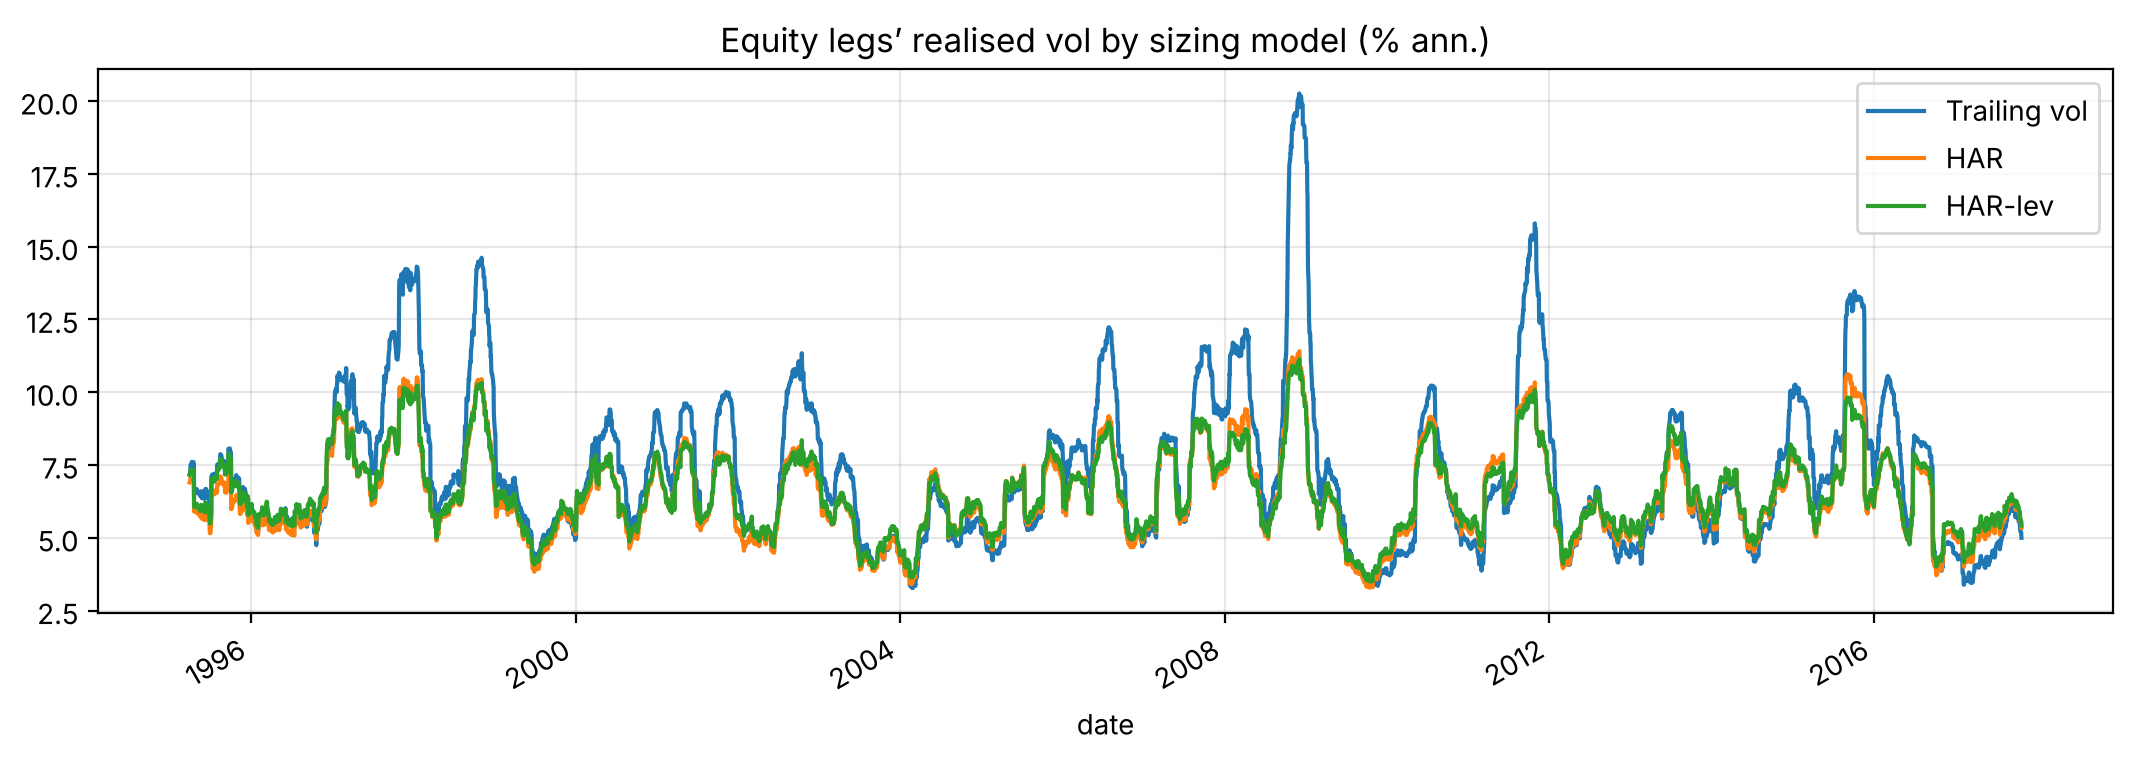

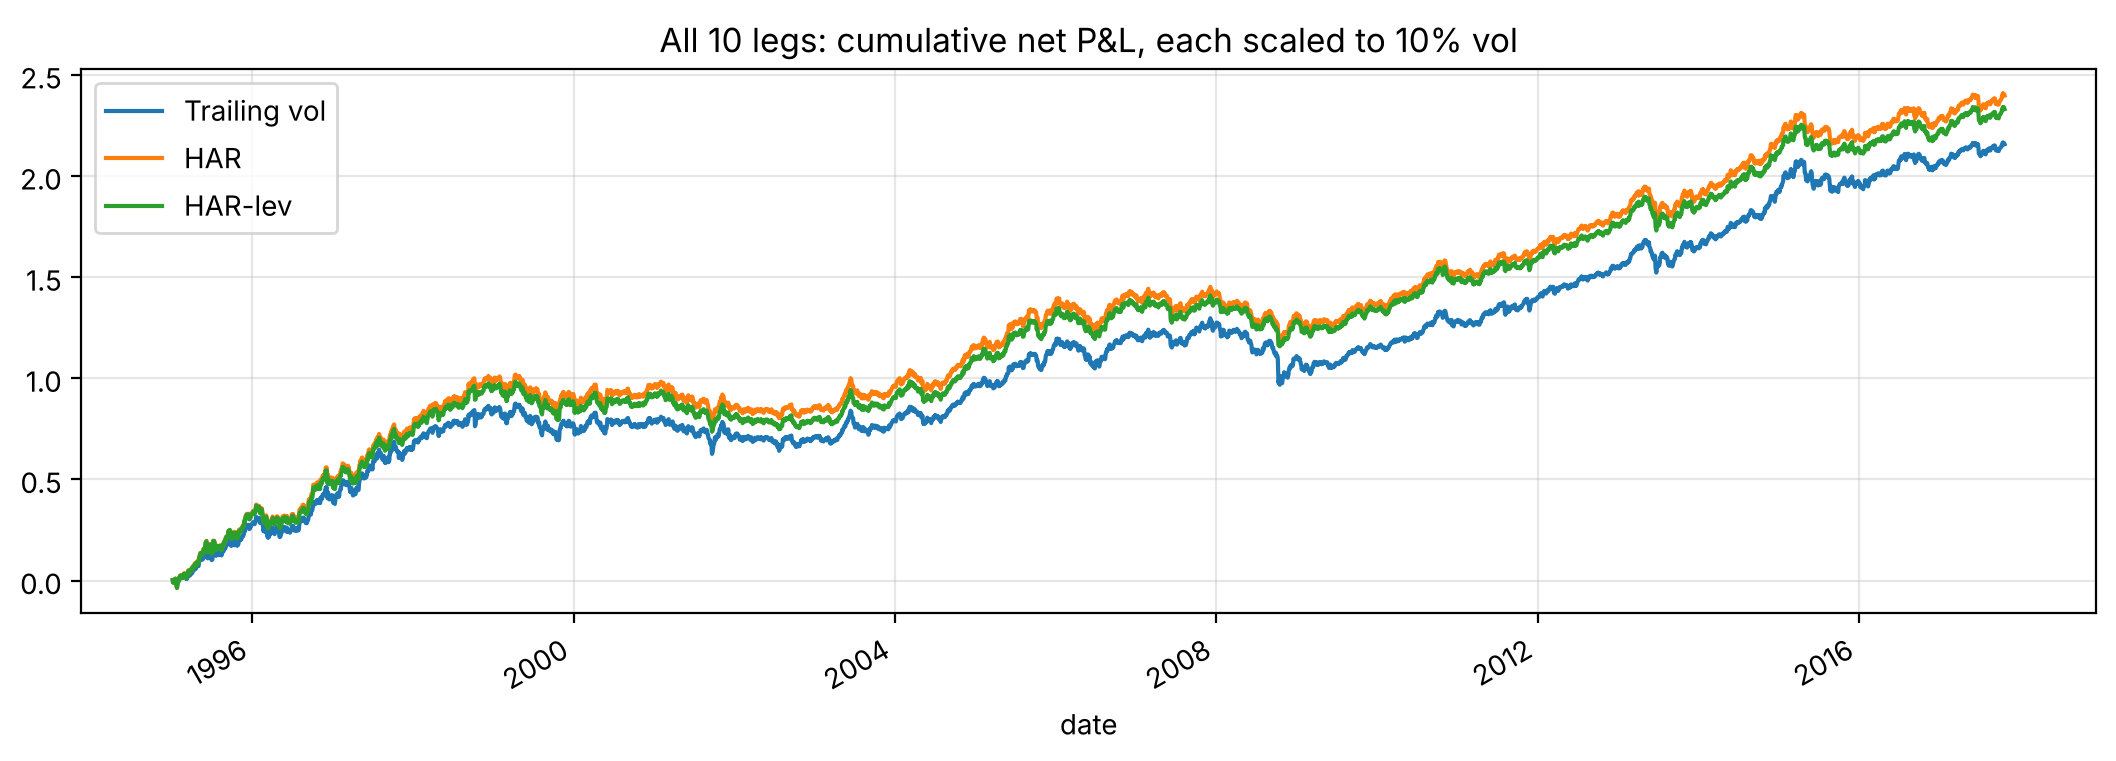

In [19]:
fig, ax = plt.subplots()
for name in STRATEGIES:
    (100 * np.sqrt(252) * PNL[("EQ", name)].rolling(63).std()).plot(ax=ax, label=name)
ax.set_title("Equity legs’ realised vol by sizing model (% ann.)")
ax.legend()
plt.show()

fig, ax = plt.subplots()
for name in STRATEGIES:
    pnl = PNL[("ALL", name)]
    (pnl / pnl.std() * TARGET_VOL / np.sqrt(252)).cumsum().plot(ax=ax, label=name)
ax.set_title("All 10 legs: cumulative net P&L, each scaled to 10% vol")
ax.legend()
plt.show()

**Findings**

HAR cuts real risk, not just forecast noise: equity risk swings half as much (vol of vol 2.7 → 1.5); bond Sharpe 0.86 → 0.93 ($p=0.04$); total Sharpe 0.92 → 1.02 ($p=0.06$); max drawdown -14.9% → -11.0%. A 1-year trailing window simply reacts months late after a vol jump. HAR-lev gives steadier equity risk still, but lower Sharpe ($p=0.03$), possibly because the leverage effect from the equity variable forecasted a higher vol and we cut our sizing, failing to capture the equity rebound after a fall.

These p-values are single comparisons. After a Holm correction across the eight Sharpe comparisons in Steps 2 and 3, none is below 0.05 (smallest adjusted $p=0.23$; section 7), so the Sharpe gains of HAR over trailing vol and the Sharpe loss of HAR-lev against HAR are suggestive, not established. The QLIKE gains of HAR over trailing vol and of HAR-lev over HAR are significant under any correction.

**Step 3: extend model to choose direction based on momentum**

The leverage effect gives no direction signal, only sizing. Thus, we add time series momentum as a signal to decide when to long the instruments, while keeping the HAR sizing from step 2.
- **Signal:** for each lookback of 1, 3 and 12 months, a vote is **up** if the price is above its level that long ago.
- **Trend:** hold the share of up votes (1, ⅔, ⅓ or 0) of the vol-sized position.
- **Each day:** target = share × vol-sized position; trade at the next close if it is outside the band. A vote change nearly always trades; when all votes turn down, the position is closed whatever its P&L.
- **Baseline:** HAR, the same book in Step 2 — shown below for comparison.

In [20]:
LOOKBACKS = (21, 63, 252)  # 1, 3 and 12 months
SIZE_MODEL = "HAR"  # same sizing Step 2 settled on, so this isolates trend's own effect


## number of up votes at close t (0-3): lookbacks whose past return is positive; NaN until 12 months of history
def trend_votes(c):
    log_ret = np.log1p(features[c].ret)
    past = [log_ret.rolling(n).sum() for n in LOOKBACKS]
    return sum((p > 0).astype(float).where(p.notna()) for p in past)


TREND = pd.concat([trend_votes(c).rename("votes").to_frame().assign(inst=c) for c in instruments]).reset_index()


## target position = share of up votes (1, 2/3, 1/3 or 0) x vol-sized position; no votes yet -> flat
def position(forecast):
    forecast = forecast.merge(TREND, on=["date", "inst"], how="left")
    return forecast.assign(w=(forecast.w * forecast.votes / 3).fillna(0))


baseline_books, baseline_held = backtest(STRATEGIES[SIZE_MODEL], no_trade_band)
TREND_PNL, held = backtest(STRATEGIES[SIZE_MODEL], no_trade_band, adjust=position)

table = pd.DataFrame.from_dict({
    **{(cat, "HAR"): {**perf(baseline_books[cat], baseline_held.get(cat)), "compared_to": ""} for cat in ("EQ", "BD", "ALL")},
    **{(cat, "HAR-trend"): {
        **perf(TREND_PNL[cat], held.get(cat)), "compared_to": "HAR",
        "sharpe_p_value": sharpe_p_value(TREND_PNL[cat], baseline_books[cat]),
    } for cat in ("EQ", "BD", "ALL")},
}, orient="index")

for cat in ("EQ", "BD", "ALL"):
    print(cat)
    display(table.loc[cat])

EQ


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
HAR,1.504,6.616,0.227,-42.965,1.509,1.269,,NaN
HAR-trend,1.427,3.999,0.357,-13.068,1.627,8.320,HAR,0.352


BD


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
HAR,6.617,7.144,0.926,-20.028,1.028,3.895,,NaN
HAR-trend,4.849,5.322,0.911,-11.641,1.703,27.469,HAR,0.87


ALL


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,compared_to,sharpe_p_value
HAR,4.277,4.201,1.018,-10.972,0.977,2.582,,NaN
HAR-trend,3.304,3.165,1.044,-6.940,0.902,17.894,HAR,0.86


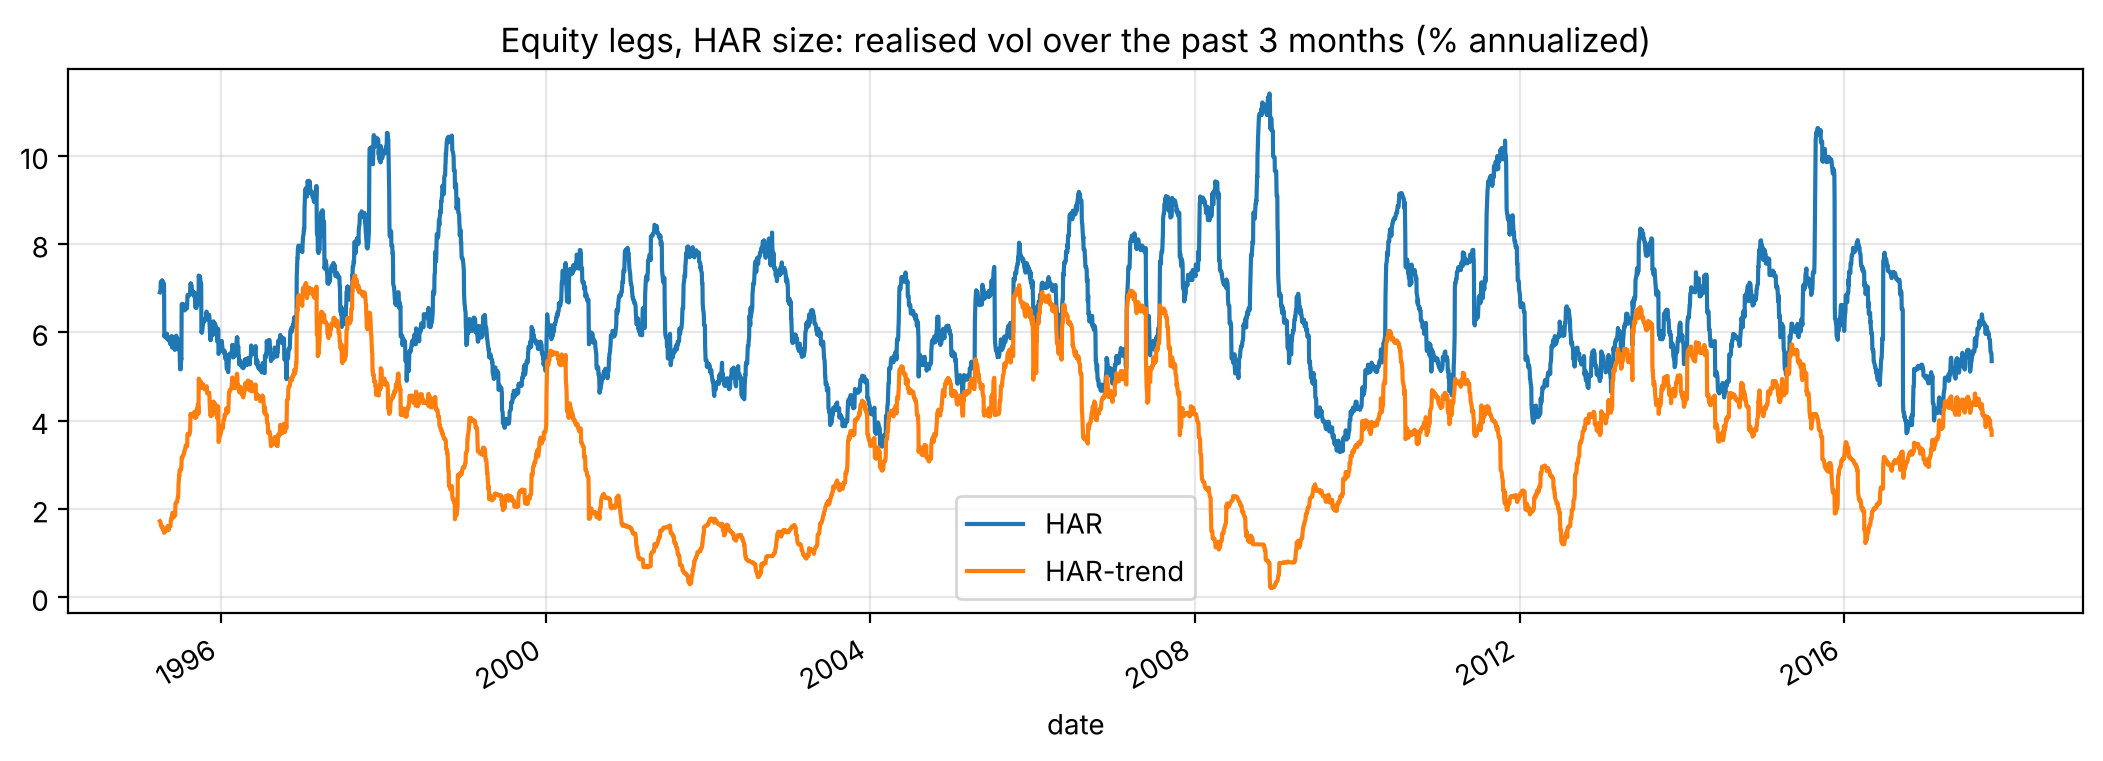

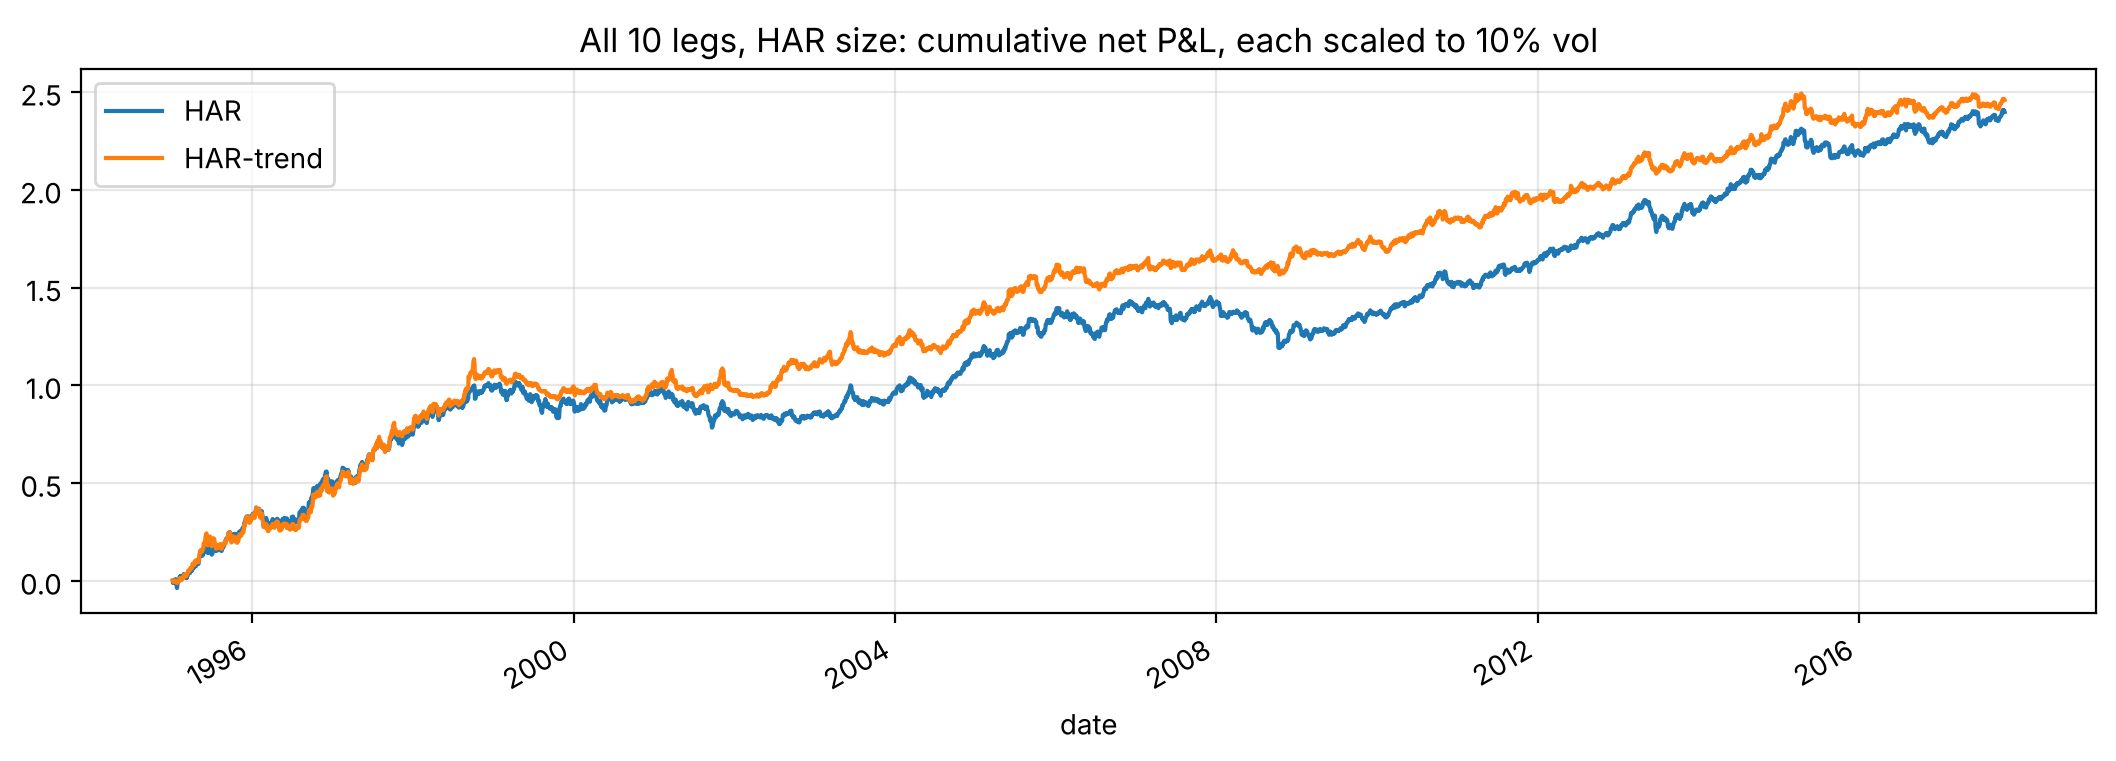

In [21]:
fig, ax = plt.subplots()
(100 * np.sqrt(252) * baseline_books["EQ"].rolling(63).std()).plot(ax=ax, label="HAR")
(100 * np.sqrt(252) * TREND_PNL["EQ"].rolling(63).std()).plot(ax=ax, label="HAR-trend")
ax.set_title(f"Equity legs, {SIZE_MODEL} size: realised vol over the past 3 months (% annualized)")
ax.legend()
plt.show()

fig, ax = plt.subplots()
for name, pnl in (("HAR", baseline_books["ALL"]), ("HAR-trend", TREND_PNL["ALL"])):
    (pnl / pnl.std() * TARGET_VOL / np.sqrt(252)).cumsum().plot(ax=ax, label=name)
ax.set_title(f"All 10 legs, {SIZE_MODEL} size: cumulative net P&L, each scaled to 10% vol")
ax.legend()
plt.show()

**Conclusion**

**HAR-trend vs. HAR:** Sharpe 1.04 vs 1.02 ($p=0.86$, not significant). Vol fell about a quarter (3.2% vs 4.2%) but max drawdown fell over a third (-6.9% vs -11.0%), a bigger fall than than scaling down holdings alone would give, so part of it is a real reduction in risk shape, not just smaller positions. The gain comes from equities (Sharpe 0.23 → 0.36; chart).

Realistically, HAR-trend is not significantly better than HAR.

## 6. Insights

- **Where the Sharpe comes from:**
    - mostly bonds (Sharpe 0.93 vs 0.23 for equities) and the negative stock-bond correlation (-0.26 between the two books).
- **Data frequency:**
    - with daily closes we cannot see vol move within the day, and trading at the next close may be too slow to act on the leverage effect, which starts the day after a fall.
- **Risk models vs sizing models:**
    - HAR-lev model is more accurate for vol forecasts, so it's better for controlling risks.
    - HAR earns a higher Sharpe than HAR-lev ($p=0.03$ on its own, not significant after Holm correction across the Sharpe comparisons), possibly because the leverage terms cut the exposure right after falls, and we cannot capture the returns from the equities rebound (again, might be more suitable for higher frequency).
- **Cross-sectional momentum:**
    - with index constituent data, we continue this strategy but build a market neutral portfolio instead by longing the past 12-month winners and shorting the losers within an index.


## 7. Inference checks

Robustness of the standard errors and p-values used above; `docs/STATISTICAL_REVIEW.md` discusses each one. Nothing here changes a model or a backtest.

- **Q3 / Q4, Newey-West lags.** The 5-day targets overlap, so regression errors are at least MA(4). 10 lags is the Newey-West rule of thumb $4(T/100)^{2/9}\approx10$ for $T\approx6500$; 22 and 44 lags check that longer volatility persistence does not change the conclusions.
- **Q4, timing.** The source market's previous-day return $y_{t-1}$ replaces $y_t$, removing any reliance on both markets closing at the same time.
- **Q5, Diebold-Mariano.** Lag sensitivity, plus the Harvey-Leybourne-Newbold small-sample correction (forecast horizon $h=5$, $t_{T-1}$ reference).
- **Q5, Sharpe tests.** The 21-day block bootstrap at other block lengths, and the Ledoit-Wolf (2008) delta-method test of a Sharpe difference with Newey-West covariance, as a studentised cross-check. Holm correction across the eight Sharpe comparisons of Steps 2 and 3.

In [22]:
from scipy.stats import t as t_dist

LAGS = (10, 22, 44)

## Q3: p-value of gamma (returns -> vol) and of the joint vol terms (vol -> returns) by Newey-West lags
q3_lags = {}
for inst in instruments:
    feat = features[inst].assign(abs_ret_norm=features[inst].ret_norm.abs())
    row = {}
    for lags in LAGS:
        row[f"gamma_p_{lags}"] = hac_ols(feat.fwd_var_5d, feat[HAR + RET], lags=lags).pvalues["ret_norm"]
    for lags in LAGS:
        row[f"beta_p_{lags}"] = float(hac_ols(feat.fwd_ret_5d, feat[HAR + RET], lags=lags).f_test(VOL_TERMS_ZERO).pvalue)
    q3_lags[inst] = row
print("Q3: p-values by Newey-West lags")
display(pd.DataFrame(q3_lags).T)


## Q4: source coefficient by lags, and with the source's previous-day return
def cross_coef(target, source, lags=2 * H, shift=0):
    src_ret = source.ret_norm.shift(shift).reindex(target.index)
    data = target.assign(abs_ret_norm=target.ret_norm.abs(), src_ret=src_ret, src_abs_ret=src_ret.abs()
                         ).dropna(subset=HAR + RET + SRC + ["fwd_var_5d"])
    fit = hac_ols(data.fwd_var_5d, data[HAR + RET + SRC], lags=lags)
    return fit.params["src_ret"], fit.pvalues["src_ret"]


q4_checks = {}
for direction, regs in (("eq → bd", eq_to_bd), ("bd → eq", bd_to_eq)):
    for name, (target, source) in regs.items():
        row = {f"p_{lags}": cross_coef(target, source, lags)[1] for lags in LAGS}
        row["theta_prev_day"], row["p_prev_day"] = cross_coef(target, source, shift=1)
        q4_checks[(direction, name)] = row
print("Q4: source-return p-value by lags, and with y_{t-1}")
display(pd.DataFrame(q4_checks).T)


## Q5: Diebold-Mariano by lags, and the Harvey-Leybourne-Newbold correction
def dm_daily_diff(cat, name):
    both = pd.concat({"model": qlike(forecasts[(cat, name)]), "prev": qlike(forecasts[(cat, PREVIOUS[name])]),
                      "date": forecasts[(cat, name)].date}, axis=1).dropna()
    return (both.model - both.prev).groupby(both.date).mean()


dm_checks = {}
for cat, name in (("EQ", "HAR"), ("EQ", "HAR-lev"), ("BD", "HAR"), ("BD", "HAR-lev-cross")):
    d = dm_daily_diff(cat, name)
    n = len(d)
    row = {f"p_{lags}": 2 * norm.sf(abs(hac_mean_t(d, lags))) for lags in (4,) + LAGS}
    hln = np.sqrt((n + 1 - 2 * H + H * (H - 1) / n) / n)
    row["p_hln"] = 2 * t_dist.sf(abs(hac_mean_t(d, 2 * H) * hln), n - 1)
    dm_checks[(cat, name)] = row
print("Diebold-Mariano p-values")
display(pd.DataFrame(dm_checks).T)


## Q5: Sharpe-difference tests
def lw_sharpe_p(pnl_a, pnl_b, lags=2 * H):
    """Ledoit-Wolf (2008) test of SR_a = SR_b: delta method with a Newey-West (Bartlett) covariance."""
    x = pd.concat([pnl_a, pnl_b], axis=1).dropna().values
    n = len(x)
    m, g = x.mean(0), (x ** 2).mean(0)
    v = np.column_stack([x - m, x ** 2 - g])
    cov = v.T @ v / n
    for lag in range(1, lags + 1):
        gam = v[lag:].T @ v[:-lag] / n
        cov += (1 - lag / (lags + 1)) * (gam + gam.T)
    var = g - m ** 2
    grad = np.array([g[0] / var[0] ** 1.5, -g[1] / var[1] ** 1.5, -0.5 * m[0] / var[0] ** 1.5, 0.5 * m[1] / var[1] ** 1.5])
    diff = m[0] / np.sqrt(var[0]) - m[1] / np.sqrt(var[1])
    return 2 * norm.sf(abs(diff) / np.sqrt(grad @ cov @ grad / n))


def holm_adjust(p):
    order, out, running = p.sort_values().index, pd.Series(index=p.index, dtype=float), 0.0
    for k, name in enumerate(order):
        running = max(running, min(1.0, (len(p) - k) * p[name]))
        out[name] = running
    return out


comparisons = {}
for cat in ("EQ", "BD", "ALL"):
    comparisons[(cat, "HAR vs Trailing vol")] = (PNL[(cat, "HAR")], PNL[(cat, "Trailing vol")])
    if cat != "BD":
        comparisons[(cat, "HAR-lev vs HAR")] = (PNL[(cat, "HAR-lev")], PNL[(cat, "HAR")])
    comparisons[(cat, "HAR-trend vs HAR")] = (TREND_PNL[cat], baseline_books[cat])

sharpe_checks = pd.DataFrame({
    key: {"p_block_21": sharpe_p_value(a, b), **{f"p_block_{blk}": sharpe_p_value(a, b, block=blk) for blk in (5, 10, 63)},
          "p_ledoit_wolf": lw_sharpe_p(a, b)}
    for key, (a, b) in comparisons.items()}).T
sharpe_checks["p_holm_8"] = holm_adjust(sharpe_checks.p_block_21)
sharpe_checks.loc["ALL", "p_holm_ALL_3"] = holm_adjust(sharpe_checks.loc["ALL", "p_block_21"]).values
print("Sharpe-difference p-values")
sharpe_checks

Q3: p-values by Newey-West lags


,gamma_p_10,gamma_p_22,gamma_p_44,beta_p_10,beta_p_22,beta_p_44
INST0,3.037e-02,2.657e-02,2.430e-02,9.620e-01,9.619e-01,9.557e-01
INST1,4.490e-01,4.176e-01,3.884e-01,9.780e-01,9.791e-01,9.791e-01
INST2,9.304e-05,3.520e-05,4.348e-05,7.269e-01,6.947e-01,6.377e-01
INST3,6.723e-02,6.902e-02,7.454e-02,1.511e-01,1.828e-01,2.094e-01
INST4,1.352e-02,1.406e-02,1.885e-02,8.667e-02,7.946e-02,7.929e-02
INST5,6.380e-07,2.729e-06,2.385e-06,7.214e-01,7.501e-01,7.697e-01
INST6,2.056e-08,5.580e-08,5.968e-08,2.900e-01,2.659e-01,1.818e-01
INST7,3.348e-07,9.299e-07,1.455e-06,3.008e-02,2.513e-02,2.519e-02
INST8,4.388e-10,5.180e-11,3.755e-11,2.197e-01,1.569e-01,1.664e-01
INST9,2.654e-05,1.329e-05,6.330e-06,3.126e-06,1.223e-08,1.027e-12


Q4: source-return p-value by lags, and with y_{t-1}


p_10   p_22   p_44  theta_prev_day  p_prev_day
eq → bd basket         0.018  0.018  0.018          -0.036       0.008
        INST6 → INST0  0.014  0.014  0.013          -0.020       0.188
        INST5 → INST1  0.730  0.732  0.724          -0.005       0.695
        INST7 → INST2  0.447  0.430  0.433           0.008       0.653
        INST9 → INST3  0.003  0.004  0.005          -0.043       0.002
bd → eq basket         0.563  0.572  0.573          -0.026       0.704
        INST0 → INST6  0.564  0.534  0.530           0.054       0.010
        INST1 → INST5  0.899  0.895  0.891           0.071       0.054
        INST2 → INST7  0.630  0.611  0.613           0.051       0.099
        INST3 → INST9  0.872  0.873  0.871           0.014       0.658

Diebold-Mariano p-values


p_4       p_10       p_22       p_44      p_hln
EQ HAR            1.701e-17  6.180e-11  6.904e-08  1.584e-06  6.921e-11
   HAR-lev        1.426e-09  1.132e-08  1.965e-08  2.823e-08  1.218e-08
BD HAR            7.659e-26  1.197e-17  2.138e-14  2.703e-12  1.593e-17
   HAR-lev-cross  7.103e-02  8.987e-02  1.044e-01  1.198e-01  9.017e-02

Sharpe-difference p-values


p_block_21  p_block_5  p_block_10  p_block_63  \
EQ  HAR vs Trailing vol       0.620      0.617       0.589       0.643   
    HAR-lev vs HAR            0.029      0.047       0.037       0.036   
    HAR-trend vs HAR          0.352      0.331       0.341       0.363   
BD  HAR vs Trailing vol       0.044      0.071       0.052       0.046   
    HAR-trend vs HAR          0.870      0.886       0.846       0.854   
ALL HAR vs Trailing vol       0.055      0.054       0.047       0.067   
    HAR-lev vs HAR            0.030      0.045       0.039       0.034   
    HAR-trend vs HAR          0.860      0.836       0.838       0.832   

                         p_ledoit_wolf  p_holm_8  p_holm_ALL_3  
EQ  HAR vs Trailing vol          0.611     1.000           NaN  
    HAR-lev vs HAR               0.041     0.232           NaN  
    HAR-trend vs HAR             0.349     1.000           NaN  
BD  HAR vs Trailing vol          0.048     0.264           NaN  
    HAR-trend vs HAR             0.871     1.000           NaN  
ALL HAR vs Trailing vol          0.047     0.275          0.11  
    HAR-lev vs HAR               0.040     0.232          0.09  
    HAR-trend vs HAR             0.847     1.000          0.86